# CrunchME: income of selected ME-focused charities worldwide

Visual **2026-11-14-01**. Frozen snapshot reviewed **19 November 2026**, covering financial years ending **2000–2024**.

## Summary

The selected charities recorded about **US$19.7m in 2024**. The highest subtotal shown is **US$20.6m in 2022**. Their 2020–2024 average is **US$19.1m a year**.

This measures **whole-charity income, not biomedical research spending or donations alone**. It includes charities that fund biomedical ME research, but their income can also support care, advocacy and other activities. This is not a complete global census. Earlier coverage is less complete, so the bars do not establish an exact global growth rate.

Choose **Runtime → Run all** in Google Colab. No BigQuery access, credentials, Drive mount or private files are needed. These are the inputs used for the published visual, not a live feed. Later accounts and reviews may change the picture.

## Methods

We began with CrunchME's biomedical-research charity directory, then added important historical organisations. Broader foundation and university budgets are outside scope. PolyBio and CODA/Metrodora whole income are not treated as ME-focused income. No unverified figure is estimated to fill a gap. The window stops at 2024 because 2025 reporting is incomplete.

Years refer to each charity's **financial year ending**. Accounting periods and income definitions differ. Actual short formation, closure and transition periods are included without annualising. Cash and accrual accounts can recognise income in different years. Income can include legacies, investments, clinic fees and public support, not just donations.

### Currency and overlap

Original currency amounts and conversion rates remain visible below. CrunchME averages daily USD-per-local-currency cross-rates from the **European Central Bank (ECB)** over each reporting period. USD amounts are unchanged. Rates and the income series are not adjusted for inflation. The supplied factors reproduce the published calculation; this notebook does not download fresh rates.

[ECB reference rates, available free of charge](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html) · [ECB reuse conditions](https://www.ecb.europa.eu/services/using-our-site/disclaimer/html/index.en.html). These are CrunchME calculations derived from ECB rates, not ECB charity-income statistics.

OMF Network uses audited group income from 2019, replacing rather than adding the US, Canadian and Australian affiliate amounts. Before 2019 the series is US-only. We group OMF with the US by its base, not donor or research location. Invest in ME and Invest in ME Research share one display series but retain separate legal-entity records. No additional inter-entity transfer was identified in reviewed accounts; that is not proof that none occurred.

We deduct identified internal grants where possible, using payer-year timing when both parties appear. This is a provisional overlap adjustment, not a fully matched recipient-year reconciliation. Irish deductions include named onward grants and disclosed fundraising-party receipts. German adjustments remove returned grant principal and identified internal regional receipts. Original source income, the signed adjustment and the resulting figure remain separate. Some unidentified or unmatched transfers may remain. No amount is invented for Emerge's unquantified OMF Australia support.

### Historical additions reviewed on 19 November

The Bateman Horne Center series now includes its OFFER predecessor from 2004–2015, under the same legal identifier (EIN 87-0687610). It does not include earlier private-clinic turnover. The amended 2013 filing supplies US$109,370, rather than the blank original return. For 2015 we combine the filed income of US$351,346 with the 2016 audit's explicit US$79,169 correction, giving US$430,515 before overlap adjustments. The existing 2016 figure already reflects that correction, so it is not deducted again. CFI's recovered 2018 return adds US$400,469.

Three provisional payer-year deductions remove US$10,000 from Solve in 2008 and US$48,018 from BHC in 2015. The parties' annual recognition dates are not fully matched. These changes add US$1,261,760 across the historical series. The 2024 figure, peak, minimum and 2020–2024 average are unchanged. The evidence table below preserves each calculation and its source.

In [1]:
import io, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
OUTPUT = Path('crunchme-charity-income-output')
OUTPUT.mkdir(exist_ok=True)


## Financial facts and source links

Each observation retains its source URL and page/table locator. `amount_original_currency × fx_usd_per_original_unit` reproduces `source_income_usd`. Adding the signed `payer_year_adjustment_usd` gives the plotted `income_usd`. Some adjustments are accounting normalisation rather than an intercharity grant; read the row's notes and linked review tables. The published £1/A$1 source-line discrepancies are immaterial and are recorded rather than used to discard a year.

In [2]:
income_csv = 'reporting_unit_id,display_name,organisation_id,country_code,period_start,period_end,period_status,reporting_year_end,amount_original_currency,currency,fx_usd_per_original_unit,fx_business_days,precision,entity_scope,accounting_basis,source_url,source_locator,source_income_usd,payer_year_adjustment_usd,income_usd,stack_id,notes,derivation,display_country,display_stack_id\n1592a60c4996810fb8a3f9d79af691a0,Invest in ME Research,1592a60c4996810fb8a3f9d79af691a0,GB,2018-10-01 00:00:00,2019-09-30 00:00:00,full_year,2019,214258.0,GBP,1.2762776158569482,255.0,exact,legal_entity,"Cash receipts and payments, not accruals",https://register-of-charities.charitycommission.gov.uk/en/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A11046045&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=5039038&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,PDF p.11; CC16a A1; excludes asset/investment sales,273452.689418278,0.0,273452.689418278,other-included,,,GB,invest-in-me-family\n1592a60c4996810fb8a3f9d79af691a0,Invest in ME Research,1592a60c4996810fb8a3f9d79af691a0,GB,2019-10-01 00:00:00,2020-09-30 00:00:00,full_year,2020,61026.0,GBP,1.275259306807386,256.0,exact,legal_entity,"Cash receipts and payments, not accruals",https://register-of-charities.charitycommission.gov.uk/en/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A11046045&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=5039038&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,PDF p.11; CC16a A1; excludes asset/investment sales,77823.97445722752,0.0,77823.97445722752,other-included,,,GB,invest-in-me-family\n1592a60c4996810fb8a3f9d79af691a0,Invest in ME Research,1592a60c4996810fb8a3f9d79af691a0,GB,2020-10-01 00:00:00,2021-09-30 00:00:00,full_year,2021,161990.0,GBP,1.3688542961121504,257.0,exact,legal_entity,"Cash receipts and payments, not accruals",https://register-of-charities.charitycommission.gov.uk/en/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A13509344&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=5039038&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,PDF p.11; CC16a A1; excludes asset/investment sales,221740.70742720724,0.0,221740.70742720724,other-included,,,GB,invest-in-me-family\n1592a60c4996810fb8a3f9d79af691a0,Invest in ME Research,1592a60c4996810fb8a3f9d79af691a0,GB,2021-10-01 00:00:00,2022-09-30 00:00:00,full_year,2022,363811.0,GBP,1.280186658172749,259.0,exact,legal_entity,"Cash receipts and payments, not accruals",https://register-of-charities.charitycommission.gov.uk/en/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A13509344&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=5039038&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,PDF p.11; CC16a A1; excludes asset/investment sales,465745.988296486,0.0,465745.988296486,other-included,,,GB,invest-in-me-family\n1592a60c4996810fb8a3f9d79af691a0,Invest in ME Research,1592a60c4996810fb8a3f9d79af691a0,GB,2022-10-01 00:00:00,2023-09-30 00:00:00,full_year,2023,65248.0,GBP,1.226718380147926,256.0,exact,legal_entity,"Cash receipts and payments, not accruals",https://register-of-charities.charitycommission.gov.uk/en/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A17243791&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=5039038&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,PDF p.10; CC16a A1; excludes asset/investment sales,80040.92086789188,0.0,80040.92086789188,other-included,,,GB,invest-in-me-family\n1592a60c4996810fb8a3f9d79af691a0,Invest in ME Research,1592a60c4996810fb8a3f9d79af691a0,GB,2023-10-01 00:00:00,2024-09-30 00:00:00,full_year,2024,112945.0,GBP,1.267961456184104,255.0,exact,legal_entity,"Cash receipts and payments, not accruals",https://register-of-charities.charitycommission.gov.uk/en/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A17243791&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=5039038&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,PDF p.10; CC16a A1; excludes asset/investment sales,143209.9066687136,0.0,143209.9066687136,other-included,,,GB,invest-in-me-family\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2000-01-01 00:00:00,2000-12-31 00:00:00,full_year,2000,1863105.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2000-AR.pdf,PDF p.9; Statement of Activities; total for reporting year,1863105.0,0.0,1863105.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2001-01-01 00:00:00,2001-12-31 00:00:00,full_year,2001,2067759.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2001-ar.pdf,PDF p.12; Statement of Activities; total for reporting year,2067759.0,0.0,2067759.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2002-01-01 00:00:00,2002-12-31 00:00:00,full_year,2002,1518143.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2002-ar.pdf,PDF p.16; Statement of Activities; total for reporting year,1518143.0,0.0,1518143.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2003-01-01 00:00:00,2003-12-31 00:00:00,full_year,2003,1874421.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2003-ar.pdf,PDF p.16; Statement of Activities; total for reporting year,1874421.0,0.0,1874421.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2004-01-01 00:00:00,2004-12-31 00:00:00,full_year,2004,1927019.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2004-ar.pdf,PDF p.16; Statement of Activities; total for reporting year,1927019.0,0.0,1927019.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2005-01-01 00:00:00,2005-12-31 00:00:00,full_year,2005,2191612.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2005-ar.pdf,PDF p.20; Statement of Activities; total for reporting year,2191612.0,0.0,2191612.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2006-01-01 00:00:00,2006-12-31 00:00:00,full_year,2006,4542066.0,USD,1.0,0.0,exact,legal_entity,Filed IRS Form 990 accrual revenue,https://990s.foundationcenter.org/990_pdf_archive/561/561683450/561683450_200612_990.pdf,"PDF p.1; Form 990 Part I line 12; calendar 2006, current year",4542066.0,0.0,4542066.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2007-01-01 00:00:00,2007-12-31 00:00:00,full_year,2007,3354277.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2008-ar.pdf,PDF p.4; Statement of Activities; comparative 2007 total,3354277.0,0.0,3354277.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2008-01-01 00:00:00,2008-12-31 00:00:00,full_year,2008,1918102.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2008-ar.pdf,PDF p.4; Statement of Activities; total for reporting year,1918102.0,-10000.0,1908102.0,1592a60c499681148667deb15260d7b5,history18-offer-solve-2008-july: provisional internal-grant deduction in payer year; history18-offer-solve-2008-november: provisional internal-grant deduction in payer year,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2009-01-01 00:00:00,2009-12-31 00:00:00,full_year,2009,1161591.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2009-ar.pdf,PDF p.9; Statement of Activities; total for reporting year,1161591.0,0.0,1161591.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2010-01-01 00:00:00,2010-12-31 00:00:00,full_year,2010,1327885.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2010-ar.pdf,PDF p.10; Statement of Activities; total for reporting year,1327885.0,0.0,1327885.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2011-01-01 00:00:00,2011-12-31 00:00:00,full_year,2011,1219911.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2013/09/2011-ar.pdf,PDF p.11; Statement of Activities; total for reporting year,1219911.0,0.0,1219911.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2012-01-01 00:00:00,2012-12-31 00:00:00,full_year,2012,1104169.0,USD,1.0,0.0,exact,legal_entity,"US accruals; total support and revenue, all donor restriction classes",https://solvecfs.org/wp-content/uploads/2022/01/2013-Audited-Financial-Statements.pdf,PDF p.5 (printed p.3); Statement of Activities; comparative 2012 total,1104169.0,0.0,1104169.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,2281889.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2022/01/2014-990.pdf,PDF p.4; Form 990 Part I line 12; Prior Year,2281889.0,0.0,2281889.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,1316641.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2022/01/2014-990.pdf,PDF p.4; Form 990 Part I line 12; Current Year,1316641.0,0.0,1316641.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,1381984.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2022/01/2015-SMCI-Form-990-Final.pdf,PDF p.3; Form 990 Part I line 12; Current Year,1381984.0,0.0,1381984.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2016-07-01 00:00:00,2017-06-30 00:00:00,full_year,2017,1798173.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2018/02/2016-SME-990-PUBLIC-DISCLOSURE-COPY-2.pdf,PDF p.1; Form 990 Part I line 12; Current Year,1798173.0,0.0,1798173.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2017-07-01 00:00:00,2018-06-30 00:00:00,full_year,2018,1713296.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2018/11/SMCFS-2018-FORM-990-PDC.pdf,PDF p.1; Form 990 Part I line 12; Current Year,1713296.0,0.0,1713296.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2018-07-01 00:00:00,2019-06-30 00:00:00,full_year,2019,2596294.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2022/01/2019-SOLVE-ME-990-PUBLIC-DISCLOSURE-COPY.pdf,PDF p.1; Form 990 Part I line 12; Current Year,2596294.0,0.0,2596294.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2019-07-01 00:00:00,2020-06-30 00:00:00,full_year,2020,3669548.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2021/07/SOLVE-ME-2019-990-PDC-FYE-6-30-20.pdf,PDF p.2; Form 990 Part I line 12; Current Year,3669548.0,0.0,3669548.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2020-07-01 00:00:00,2021-06-30 00:00:00,full_year,2021,2192325.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2023/04/Fiscal-Year-2020-2021-990-Form.pdf,PDF p.2; Form 990 Part I line 12; Current Year,2192325.0,0.0,2192325.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2021-07-01 00:00:00,2022-06-30 00:00:00,full_year,2022,5520483.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2023/10/990-FY-22-Public-2.pdf,PDF p.2; Form 990 Part I line 12; Current Year,5520483.0,0.0,5520483.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2022-07-01 00:00:00,2023-06-30 00:00:00,full_year,2023,2037881.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2024/05/SOLVEMECFSINITIATIVEINC-2022-Form-990-Public-Disclosure-Copy.pdf,PDF p.2; Form 990 Part I line 12; Current Year,2037881.0,0.0,2037881.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2023-07-01 00:00:00,2024-06-30 00:00:00,full_year,2024,1947106.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 revenue; not automatically identical to audited GAAP support,https://solvecfs.org/wp-content/uploads/2025/04/SOLVEMECFSINITIATIVEINC-2023-6-30-24-Form-990.pdf,PDF p.1; Form 990 Part I line 12; Current Year,1947106.0,0.0,1947106.0,1592a60c499681148667deb15260d7b5,,,US,1592a60c499681148667deb15260d7b5\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2000-01-01 00:00:00,2000-12-31 00:00:00,full_year,2000,420090.0,GBP,1.5150576178483788,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/ODY3MzY3MzFhZGlxemtjeA/document?format=pdf&download=0,PDF p.10; charity statement; 2000 total,636460.5546819255,0.0,636460.5546819255,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2001-01-01 00:00:00,2001-12-31 00:00:00,full_year,2001,363779.0,GBP,1.4399678098731714,254.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/ODY3MzY3MzFhZGlxemtjeA/document?format=pdf&download=0,PDF p.10; charity statement; 2001 total,523830.0499078524,0.0,523830.0499078524,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2002-01-01 00:00:00,2002-12-31 00:00:00,full_year,2002,316390.0,GBP,1.5028505425959806,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MTM0ODMwODkyYWRpcXprY3g/document?format=pdf&download=0,PDF p.12; charity statement; 2002 total,475486.8831719423,0.0,475486.8831719423,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2003-01-01 00:00:00,2003-12-31 00:00:00,full_year,2003,369001.0,GBP,1.6343349921750556,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MTM0ODMwODkyYWRpcXprY3g/document?format=pdf&download=0,PDF p.12; charity statement; 2003 total,603071.2464475877,0.0,603071.2464475877,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2004-01-01 00:00:00,2004-12-31 00:00:00,full_year,2004,212888.0,GBP,1.8326253405545592,259.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MTcxMzM0NTk4YWRpcXprY3g/document?format=pdf&download=0,"Consolidated SOFA and PDF p.18, note2 subsidiary results, 2004 column",390143.94349997904,0.0,390143.94349997904,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2005-01-01 00:00:00,2005-12-31 00:00:00,full_year,2005,219506.0,GBP,1.819114208279988,257.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MTcxMzM0NTk4YWRpcXprY3g/document?format=pdf&download=0,"Consolidated SOFA and PDF p.18, note2 subsidiary results, 2005 column",399306.48340270703,0.0,399306.48340270703,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2006-01-01 00:00:00,2006-12-31 00:00:00,full_year,2006,269011.0,GBP,1.8423470237867656,255.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MjAxNjYyNTYzM2FkaXF6a2N4/document?format=pdf&download=0,"Consolidated SOFA and PDF p.17, note2 subsidiary results, 2006 column",495611.6152159017,0.0,495611.6152159017,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2007-01-01 00:00:00,2007-12-31 00:00:00,full_year,2007,228544.0,GBP,2.002112170187059,255.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MjAxNjYyNTYzM2FkaXF6a2N4/document?format=pdf&download=0,"Consolidated SOFA and PDF p.17, note2 subsidiary results, 2007 column",457570.7238232313,0.0,457570.7238232313,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2008-01-01 00:00:00,2008-12-31 00:00:00,full_year,2008,316733.0,GBP,1.8538279837080296,256.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzAyNDYyMDA0M2FkaXF6a2N4/document?format=pdf&download=0,"Consolidated SOFA and PDF p.21, note2 subsidiary results, 2008 column",587168.4987637954,0.0,587168.4987637954,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2009-01-01 00:00:00,2009-12-31 00:00:00,full_year,2009,278012.0,GBP,1.5668440103969976,256.0,exact,legal_entity,UK charity-only accrual incoming resources; not consolidated trading-subsidiary turnover,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzA0NDkzMTMzNmFkaXF6a2N4/document?format=pdf&download=0,"PDF p.22 / printed p.20; charity SOFA, 2009 comparative; charity scope corroborated on PDF p.23",435601.4370184901,0.0,435601.4370184901,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2010-01-01 00:00:00,2010-12-31 00:00:00,full_year,2010,233963.0,GBP,1.5451980096793174,258.0,exact,legal_entity,UK charity-only accrual incoming resources; not consolidated trading-subsidiary turnover,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzA0NDkzMTMzNmFkaXF6a2N4/document?format=pdf&download=0,"PDF p.22 / printed p.20; charity SOFA, 2010 total; charity scope corroborated on PDF p.23",361519.16193860216,0.0,361519.16193860216,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2011-01-01 00:00:00,2011-12-31 00:00:00,full_year,2011,228826.0,GBP,1.603552109396936,257.0,exact,legal_entity,UK charity-only accrual incoming resources; not consolidated trading-subsidiary turnover,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzA4NjAxMTM4NWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.25 / printed p.23; charity SOFA, 2011 comparative; parent investments/balances corroborated in notes",366934.4149848633,0.0,366934.4149848633,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2012-01-01 00:00:00,2012-12-31 00:00:00,full_year,2012,496963.0,GBP,1.5844681277457324,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzEwODc2NjY1NWFkaXF6a2N4/document?format=pdf&download=0,PDF p.25; charity statement; 2012 total,787422.0341689024,0.0,787422.0341689024,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,273538.0,GBP,1.5643030957018602,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzEwODc2NjY1NWFkaXF6a2N4/document?format=pdf&download=0,PDF p.25; charity statement; 2013 total,427896.34019209543,0.0,427896.34019209543,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,264936.0,GBP,1.6476615153090146,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzE1OTkxODI0MWFkaXF6a2N4/document?format=pdf&download=0,PDF p.26; charity statement; 2014 total,436524.8512199091,0.0,436524.8512199091,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,663014.0,GBP,1.5287840391717715,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzE1OTkxODI0MWFkaXF6a2N4/document?format=pdf&download=0,PDF p.26; charity statement; 2015 total,1013605.220947433,0.0,1013605.220947433,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,771429.0,GBP,1.3550377278607173,257.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzIxNTI0MDI4OWFkaXF6a2N4/document?format=pdf&download=0,PDF p.25; charity statement; 2016 total,1045315.3993658652,0.0,1045315.3993658652,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,325997.0,GBP,1.2881614015427725,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzIxNTI0MDI4OWFkaXF6a2N4/document?format=pdf&download=0,PDF p.25; charity statement; 2017 total,419936.75241873914,0.0,419936.75241873914,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,419334.0,GBP,1.3351477739190707,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzI3ODU1MTkwNGFkaXF6a2N4/document?format=pdf&download=0,PDF p.9; charity statement; 2018 total,559872.8566285796,0.0,559872.8566285796,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2019-01-01 00:00:00,2019-12-31 00:00:00,full_year,2019,555711.0,GBP,1.276060639702556,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzI3ODU1MTkwNGFkaXF6a2N4/document?format=pdf&download=0,PDF p.9; charity statement; 2019 total,709120.9341497471,0.0,709120.9341497471,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2020-01-01 00:00:00,2020-12-31 00:00:00,full_year,2020,1109773.0,GBP,1.283892649418081,257.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzM0ODcwODM2OWFkaXF6a2N4/document?format=pdf&download=0,PDF p.11; charity statement; 2020 total,1424829.3972226516,0.0,1424829.3972226516,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2021-01-01 00:00:00,2021-12-31 00:00:00,full_year,2021,1264843.0,GBP,1.3758664079688516,258.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzM0ODcwODM2OWFkaXF6a2N4/document?format=pdf&download=0,PDF p.11; charity statement; 2021 total,1740254.9950545465,0.0,1740254.9950545465,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,860520.0,GBP,1.2360384216364615,257.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzQzNzY0MzIyM2FkaXF6a2N4/document?format=pdf&download=0,PDF p.14; charity statement; 2022 total,1063635.782586608,0.0,1063635.782586608,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,1017845.0,GBP,1.24337584080732,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzQzNzY0MzIyM2FkaXF6a2N4/document?format=pdf&download=0,PDF p.14; charity statement; 2023 total,1265563.8826865265,0.0,1265563.8826865265,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c49968114bab5f86f14ba2083,ME Association,1592a60c49968114bab5f86f14ba2083,GB,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,1118304.0,GBP,1.2785941693884644,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02361986/filing-history/MzUyOTIzNTMyNGFkaXF6a2N4/document?format=pdf&download=0,PDF p.16; charity statement; 2024 total,1429856.9740037972,0.0,1429856.9740037972,1592a60c49968114bab5f86f14ba2083,,,GB,1592a60c49968114bab5f86f14ba2083\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2013-11-01 00:00:00,2014-10-31 00:00:00,full_year,2014,263141.0,GBP,1.656232157926555,255.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2018/05/annual-report-2015.pdf,PDF p.18; statement of financial activities; Total 2014 column,435822.5862689517,0.0,435822.5862689517,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2014-11-01 00:00:00,2015-10-31 00:00:00,full_year,2015,259117.0,GBP,1.5389790997796078,254.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2018/05/annual-report-2015.pdf,PDF p.18; statement of financial activities; Total 2015 column,398775.6473975926,0.0,398775.6473975926,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2015-11-01 00:00:00,2016-10-31 00:00:00,full_year,2016,237952.0,GBP,1.3990439787416336,257.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2018/05/annual-report-2016.pdf,PDF p.16; statement of financial activities; Total 2016 column,332905.31282952917,0.0,332905.31282952917,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2016-11-01 00:00:00,2017-10-31 00:00:00,full_year,2017,221315.0,GBP,1.2742536586287925,257.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2018/05/annual-report-2017.pdf,PDF p.17; statement of financial activities; Total 2017 column,282011.4484594312,0.0,282011.4484594312,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2017-11-01 00:00:00,2018-10-31 00:00:00,full_year,2018,272398.0,GBP,1.3433293230558987,255.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2019/04/annual-report-2018.pdf,PDF p.18; statement of financial activities; Total 2018 column,365920.2209417807,0.0,365920.2209417807,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2018-11-01 00:00:00,2019-10-31 00:00:00,full_year,2019,1204743.0,GBP,1.27284913114757,255.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2020/06/annual-report-2019.pdf,PDF p.24; statement of financial activities; Total 2019 column,1533456.080806117,0.0,1533456.080806117,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2019-11-01 00:00:00,2020-10-31 00:00:00,full_year,2020,744736.0,GBP,1.2782957967069897,255.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2021/06/annual-report-2020.pdf,PDF p.27; statement of financial activities; Total 2020 column,951992.8984563764,0.0,951992.8984563764,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2020-11-01 00:00:00,2021-10-31 00:00:00,full_year,2021,612152.0,GBP,1.3750519515509847,256.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2022/05/annual-report-2021.pdf,PDF p.31; statement of financial activities; Total 2021 column,841740.8022458383,0.0,841740.8022458383,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2021-11-01 00:00:00,2022-10-31 00:00:00,full_year,2022,754257.0,GBP,1.260635410469874,259.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2023/05/annual-report-2022.pdf,PDF p.35; statement of financial activities; Total 2022 column,950843.0827947758,0.0,950843.0827947758,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2022-11-01 00:00:00,2023-10-31 00:00:00,full_year,2023,516571.0,GBP,1.2338882852510962,257.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2024/05/annual-report-2023.pdf,PDF p.36; statement of financial activities; Total 2023 column,637390.905400444,0.0,637390.905400444,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\n1592a60c499681349134d2ac69dd0c7e,ME Research UK,1592a60c499681349134d2ac69dd0c7e,GB,2023-11-01 00:00:00,2024-10-31 00:00:00,full_year,2024,364816.0,GBP,1.2757625493175455,256.0,exact,legal_entity,UK charity accruals; investment revaluation gains outside reported total income,https://www.meresearch.org.uk/wp-content/uploads/2025/04/annual-report-2024.pdf,PDF p.37; statement of financial activities; Total 2024 column,465418.5901918298,0.0,465418.5901918298,1592a60c499681349134d2ac69dd0c7e,,,GB,1592a60c499681349134d2ac69dd0c7e\nomf-network,Open Medicine Foundation (OMF),1592a60c49968134aa8ac37d7170e317,US,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,1506452.0,USD,1.0,0.0,exact,legal_entity,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",https://www.omf.ngo/wp-content/uploads/2023/06/2013-OMF-Form-990.pdf,PDF p.1; tax return current-year column,1506452.0,0.0,1506452.0,omf-network,,,US,omf-network\nomf-network,Open Medicine Foundation (OMF),1592a60c49968134aa8ac37d7170e317,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,462167.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 accrual revenue,https://www.omf.ngo/wp-content/uploads/2023/06/2015-OMF-Form-990.pdf,PDF p.1; Form 990 Part I line 12; Prior Year,462167.0,0.0,462167.0,omf-network,,,US,omf-network\nomf-network,Open Medicine Foundation (OMF),1592a60c49968134aa8ac37d7170e317,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,1871717.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 accrual revenue,https://www.omf.ngo/wp-content/uploads/2023/06/2015-OMF-Form-990.pdf,PDF p.1; Form 990 Part I line 12; Current Year,1871717.0,0.0,1871717.0,omf-network,,,US,omf-network\nomf-network,Open Medicine Foundation (OMF),1592a60c49968134aa8ac37d7170e317,US,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,1627743.0,USD,1.0,0.0,exact,legal_entity,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",https://www.omf.ngo/wp-content/uploads/2016/09/OMF-FS-Report-12.31.16_Final.pdf,"PDF p.6; US OMF column, not consolidated group",1627743.0,0.0,1627743.0,omf-network,,,US,omf-network\nomf-network,Open Medicine Foundation (OMF),1592a60c49968134aa8ac37d7170e317,US,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,2657107.0,USD,1.0,0.0,exact,legal_entity,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",https://ftp.omf.ngo/wp-content/uploads/2018/04/OMF-Final-Audit-Report-for-2017.pdf,"PDF p.6; US OMF column, not consolidated group",2657107.0,0.0,2657107.0,omf-network,,,US,omf-network\nomf-network,Open Medicine Foundation (OMF),1592a60c49968134aa8ac37d7170e317,US,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,8908795.0,USD,1.0,0.0,exact,legal_entity,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",https://www.omf.ngo/wp-content/uploads/2023/06/2018-OMF-Form-990.pdf,PDF p.1; tax return current-year column,8908795.0,0.0,8908795.0,omf-network,,,US,omf-network\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2015-07-01 00:00:00,2016-06-30 00:00:00,full_year,2016,59228.0,NZD,0.6680349848474045,258.0,exact,legal_entity,NZ Tier4 cash receipts,https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=a15a43a3-ffc8-4552-ad66-5a415edf1ff2&searchId=5c68174e-a4db-e711-a67f-00155d6b7730,PDF p.5; prior-year receipts column,39566.37608254208,0.0,39566.37608254208,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2016-07-01 00:00:00,2017-06-30 00:00:00,full_year,2017,85915.0,NZD,0.7128513847675717,257.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=0816b118-3ef2-48e1-80b1-0e48294c45d4&searchId=b1de85d2-fc7c-e811-bb4e-00155d6b7730,"PDF p.5; receipts/payments, prior-year column",61244.626722305926,0.0,61244.626722305926,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2017-07-01 00:00:00,2018-06-30 00:00:00,full_year,2018,48508.0,NZD,0.7147489541431081,254.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=0816b118-3ef2-48e1-80b1-0e48294c45d4&searchId=b1de85d2-fc7c-e811-bb4e-00155d6b7730,"PDF p.5; receipts/payments, current-year column",34671.04226757389,0.0,34671.04226757389,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2018-07-01 00:00:00,2019-06-30 00:00:00,full_year,2019,151378.0,NZD,0.6706950782920249,254.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=b73302ba-468a-4b04-ade5-8319d3838a59&searchId=68bdf9c8-ce9b-e911-9f99-00155d6b7730,"PDF p.4; receipts/payments, current-year column",101528.47956169014,0.0,101528.47956169014,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2019-07-01 00:00:00,2020-06-30 00:00:00,full_year,2020,39422.0,NZD,0.6367975242973746,256.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=fec7c74f-6172-470a-bfbf-fbd604be4ef9&searchId=6ea6031b-69bb-ea11-ba6c-00155d6b7730,"PDF p.4; receipts/payments, current-year column",25103.8320028511,0.0,25103.8320028511,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2020-07-01 00:00:00,2021-06-30 00:00:00,full_year,2021,1192357.0,NZD,0.6951787579060155,257.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=5b7d6706-8946-42dc-a9d3-22244e94f3d7&searchId=477f8d2d-3bda-eb11-b43a-00155d6b7730,"PDF p.4; receipts/payments, current-year column",828901.2582405428,0.0,828901.2582405428,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2021-07-01 00:00:00,2022-06-30 00:00:00,full_year,2022,34388.0,NZD,0.6808770504233695,259.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=3914c78d-3560-4d1b-b96b-495c45a80121&searchId=9a5b9a5e-dd17-ee11-bb22-0022480ffcd1,"PDF p.4; receipts/payments, prior-year column",23414.000009958832,0.0,23414.000009958832,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2022-07-01 00:00:00,2023-06-30 00:00:00,full_year,2023,56586.0,NZD,0.6162175138719556,257.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=fb9eaf68-55cf-4baa-a7d4-7a29f5aa98f9&searchId=a70b6119-7937-ef11-bb33-000d3acc4199,"PDF p.4; receipts/payments, prior-year column",34869.28423995848,0.0,34869.28423995848,other-included,,,NZ,other-NZ\n1592a60c499681459ed6d5170d4294c0,ANZMES,1592a60c499681459ed6d5170d4294c0,NZ,2023-07-01 00:00:00,2024-06-30 00:00:00,full_year,2024,52763.0,NZD,0.6064482595625847,254.0,exact,legal_entity,"NZ Tier 4 cash receipts; excludes GST, payments, opening assets and financing",https://register.charities.govt.nz/Document/DownloadPublicDocument?documentId=fb9eaf68-55cf-4baa-a7d4-7a29f5aa98f9&searchId=a70b6119-7937-ef11-bb33-000d3acc4199,"PDF p.4; receipts/payments, current-year column",31998.02951930066,0.0,31998.02951930066,other-included,,,NZ,other-NZ\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,368875.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/201603049349300255/IRS990,Form 990 Part I line 12; prior year,368875.0,0.0,368875.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,461521.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/201603049349300255/IRS990,Form 990 Part I line 12; current year,461521.0,0.0,461521.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,560242.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/201831669349300413/IRS990,Form 990 Part I line 12; prior year,560242.0,0.0,560242.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,540107.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/201831669349300413/IRS990,Form 990 Part I line 12; current year,540107.0,0.0,540107.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,481688.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/201913199349300611/IRS990,Form 990 Part I line 12; current year,481688.0,0.0,481688.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2019-01-01 00:00:00,2019-12-31 00:00:00,full_year,2019,341819.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/202003159349305720/IRS990,Form 990 Part I line 12; current year,341819.0,0.0,341819.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2020-01-01 00:00:00,2020-12-31 00:00:00,full_year,2020,668052.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/202123159349308462/IRS990,Form 990 Part I line 12; current year,668052.0,0.0,668052.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2021-01-01 00:00:00,2021-12-31 00:00:00,full_year,2021,483746.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/202213199349332666/IRS990,Form 990 Part I line 12; current year,483746.0,0.0,483746.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,297373.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/202333189349317048/IRS990,Form 990 Part I line 12; current year,297373.0,0.0,297373.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,626336.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/202403189349304575/IRS990,Form 990 Part I line 12; current year,626336.0,-35000.0,591336.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c49968147a685c4670bbcd146,Simmaron Research,1592a60c49968147a685c4670bbcd146,US,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,816332.0,USD,1.0,0.0,exact,legal_entity,IRS Form 990 reported total revenue,https://projects.propublica.org/nonprofits/full_text/202503589349300120/IRS990,Form 990 Part I line 12; current year,816332.0,-35000.0,781332.0,1592a60c49968147a685c4670bbcd146,,,US,1592a60c49968147a685c4670bbcd146\n1592a60c499681758e76f295e10ab2c1,Lost Voices Stiftung,1592a60c499681758e76f295e10ab2c1,DE,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,14604.23,EUR,1.3285007843137255,255.0,exact,legal_entity,German foundation cash receipts excluding permanent endowment additions,https://lost-voices-stiftung.jimdoweb.com/app/download/6524435664/Jahresbericht%2B2014%2Bm_Unterschrift.pdf?t=1488827330,PDF p.5; ordinary receipt lines 2–7,19401.73100929804,0.0,19401.73100929804,other-included,,,DE,other-DE\n1592a60c499681a299b4f472b048f684,Riksförbundet för ME-Patienter,1592a60c499681a299b4f472b048f684,SE,2021-01-01 00:00:00,2021-12-31 00:00:00,full_year,2021,1706453.0,SEK,0.1165812430649492,258.0,exact,legal_entity,Swedish recognised operating income plus interest; research pass-through outside operating total,https://rme.nu/wp-content/uploads/2024/04/RME-Verksamhetsberattelse-och-Arsbokslut-2023.pdf,"PDF p.23; operating-income total plus interest, before expenses and reserve allocations",198940.41197191176,0.0,198940.41197191176,other-included,,,SE,other-SE\n1592a60c499681a299b4f472b048f684,Riksförbundet för ME-Patienter,1592a60c499681a299b4f472b048f684,SE,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,1920241.0,SEK,0.0991723967804232,257.0,exact,legal_entity,Swedish recognised operating income plus interest; research pass-through outside operating total,https://rme.nu/wp-content/uploads/2024/04/RME-Verksamhetsberattelse-och-Arsbokslut-2023.pdf,"PDF p.23; operating-income total plus interest, before expenses and reserve allocations",190434.9023660366,0.0,190434.9023660366,other-included,,,SE,other-SE\n1592a60c499681a299b4f472b048f684,Riksförbundet för ME-Patienter,1592a60c499681a299b4f472b048f684,SE,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,2061591.0,SEK,0.0942480314767869,255.0,exact,legal_entity,Swedish recognised operating income plus interest; research pass-through outside operating total,https://rme.nu/wp-content/uploads/2024/04/RME-Verksamhetsberattelse-och-Arsbokslut-2023.pdf,"PDF p.23; operating-income total plus interest, before expenses and reserve allocations",194300.89346026065,0.0,194300.89346026065,other-included,,,SE,other-SE\n1592a60c499681a299b4f472b048f684,Riksförbundet för ME-Patienter,1592a60c499681a299b4f472b048f684,SE,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,2191185.0,SEK,0.0946988641075768,256.0,exact,legal_entity,Swedish annual accounts; recognised operating income plus separately disclosed interest,https://rme.nu/wp-content/uploads/2026/04/Arsredovisning-2025.pdf,PDF p4; current 2025 / comparative 2024 columns,207502.73054956069,0.0,207502.73054956069,other-included,,,SE,other-SE\n1592a60c499681a38f32f1f508c2f155,ME/CFS Research Foundation,1592a60c499681a38f32f1f508c2f155,DE,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,104409.42,EUR,1.0812686274509804,255.0,exact,legal_entity,"German HGB accruals; accountant-prepared, not an audit opinion",https://www.lobbyregister.bundestag.de/media/22/f9/527163/Jahresabschluss-zum-31-12-2023.pdf,"PDF p.10; Anlage 2; sum of income lines, excluding prior-year carryforward and reserve allocations",112894.63025635296,0.0,112894.63025635296,1592a60c499681a38f32f1f508c2f155,,,DE,1592a60c499681a38f32f1f508c2f155\n1592a60c499681a38f32f1f508c2f155,ME/CFS Research Foundation,1592a60c499681a38f32f1f508c2f155,DE,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,517632.13,EUR,1.08238046875,256.0,exact,legal_entity,"German HGB accruals; accountant-prepared, not an audit opinion",https://www.lobbyregister.bundestag.de/media/e7/96/817592/Jahresabschluss-zum-31-12-2024_fuerLobbyregister.pdf,"PDF p.10; Anlage 2; sum of income lines, excluding prior-year carryforward and reserve allocations",560274.9075094609,0.0,560274.9075094609,1592a60c499681a38f32f1f508c2f155,,,DE,1592a60c499681a38f32f1f508c2f155\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,1999-04-01 00:00:00,2000-03-31 00:00:00,full_year,2000,471708.0,GBP,1.6110140821059749,261.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/NjIyMjI3NTlhZGlxemtjeA/document?format=pdf&download=0,"PDF p.6; statement, current total",759928.2306420451,0.0,759928.2306420451,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2000-04-01 00:00:00,2001-03-31 00:00:00,full_year,2001,555719.0,GBP,1.4778901293377056,254.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MTIxNjcxOThhZGlxemtjeA/document?format=pdf&download=0,"PDF p.12; statement, comparative total",821291.6247854204,0.0,821291.6247854204,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2001-04-01 00:00:00,2002-03-31 00:00:00,full_year,2002,484285.0,GBP,1.4316263108469467,252.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MTIxNjcxOThhZGlxemtjeA/document?format=pdf&download=0,"PDF p.12; statement, current total",693315.1479485136,0.0,693315.1479485136,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2002-04-01 00:00:00,2003-03-31 00:00:00,full_year,2003,785261.0,GBP,1.5460872881816812,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/Nzk3MzMyNTNhZGlxemtjeA/document?format=pdf&download=0,"PDF p.12; statement, current total",1214082.0500048352,0.0,1214082.0500048352,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2003-04-01 00:00:00,2004-03-31 00:00:00,full_year,2004,766130.0,GBP,1.6930712942199977,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/NzYxMDc1MTJhZGlxemtjeA/document?format=pdf&download=0,"PDF p.12; statement, comparative total",1297112.710640767,0.0,1297112.710640767,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2004-04-01 00:00:00,2005-03-31 00:00:00,full_year,2005,781906.0,GBP,1.8451632679055383,257.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/NzYxMDc1MTJhZGlxemtjeA/document?format=pdf&download=0,"PDF p.12; statement, current total",1442744.230154948,0.0,1442744.230154948,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2005-04-01 00:00:00,2006-03-31 00:00:00,full_year,2006,955883.0,GBP,1.7853130817981948,260.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MTkxNjY0Mjk5YWRpcXprY3g/document?format=pdf&download=0,"PDF p.13; statement, comparative total",1706550.424568504,0.0,1706550.424568504,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2006-04-01 00:00:00,2007-03-31 00:00:00,full_year,2007,693470.0,GBP,1.8937001586049176,254.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MTkxNjY0Mjk5YWRpcXprY3g/document?format=pdf&download=0,"PDF p.13; statement, current total",1313224.2489877522,0.0,1313224.2489877522,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2007-04-01 00:00:00,2008-03-31 00:00:00,full_year,2008,949123.0,GBP,2.008302844311979,253.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzAwMzg4NzQwOWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.12; statement, comparative total",1906126.4205019183,0.0,1906126.4205019183,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2008-04-01 00:00:00,2009-03-31 00:00:00,full_year,2009,913925.0,GBP,1.7209287956641846,257.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzAwMzg4NzQwOWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.12; statement, current total",1572799.84957739,0.0,1572799.84957739,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2009-04-01 00:00:00,2010-03-31 00:00:00,full_year,2010,1031237.0,GBP,1.5974808097157895,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzA0NDQwMjIzNWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.15; statement, comparative total",1647381.3177688816,0.0,1647381.3177688816,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2010-04-01 00:00:00,2011-03-31 00:00:00,full_year,2011,1124009.0,GBP,1.5560032790302594,259.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzA0NDQwMjIzNWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.15; statement, current total",1748961.6896595228,0.0,1748961.6896595228,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2011-04-01 00:00:00,2012-03-31 00:00:00,full_year,2012,689333.0,GBP,1.5956757146732876,258.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzA4NjY4MTc2OWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.20; statement, comparative total",1099951.9274228814,0.0,1099951.9274228814,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2012-04-01 00:00:00,2013-03-31 00:00:00,full_year,2013,753243.0,GBP,1.580098938392026,253.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzA4NjY4MTc2OWFkaXF6a2N4/document?format=pdf&download=0,"PDF p.20; statement, current total",1190198.464651225,0.0,1190198.464651225,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2013-04-01 00:00:00,2014-03-31 00:00:00,full_year,2014,668844.0,GBP,1.5893881889620394,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzEzODk1MDcwNGFkaXF6a2N4/document?format=pdf&download=0,"PDF p.21; statement, comparative total",1063052.7538581262,0.0,1063052.7538581262,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2014-04-01 00:00:00,2015-03-31 00:00:00,full_year,2015,970222.0,GBP,1.6131651632741502,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzEzODk1MDcwNGFkaXF6a2N4/document?format=pdf&download=0,"PDF p.21; statement, current total",1565128.3310421726,0.0,1565128.3310421726,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2015-04-01 00:00:00,2016-03-31 00:00:00,full_year,2016,1013038.0,GBP,1.5083910297106276,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzE5MzI0MDA1MGFkaXF6a2N4/document?format=pdf&download=0,"PDF p.24; statement, comparative total",1528057.4319559948,0.0,1528057.4319559948,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2016-04-01 00:00:00,2017-03-31 00:00:00,full_year,2017,681687.0,GBP,1.3077605237287773,260.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzE5MzI0MDA1MGFkaXF6a2N4/document?format=pdf&download=0,"PDF p.24; statement, current total",891483.348139099,0.0,891483.348139099,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2017-04-01 00:00:00,2018-03-31 00:00:00,full_year,2018,1268718.0,GBP,1.3267813993945572,253.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzI0NzQ0MzYzN2FkaXF6a2N4/document?format=pdf&download=0,"PDF p.25; statement, comparative total",1683311.443477064,0.0,1683311.443477064,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2018-04-01 00:00:00,2019-03-31 00:00:00,full_year,2019,1112958.0,GBP,1.313012399697231,255.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzI0NzQ0MzYzN2FkaXF6a2N4/document?format=pdf&download=0,"PDF p.25; statement, current total",1461327.6543422306,0.0,1461327.6543422306,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2019-04-01 00:00:00,2020-03-31 00:00:00,full_year,2020,949527.0,GBP,1.2706705647719887,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzMyMTAwMjk5MmFkaXF6a2N4/document?format=pdf&download=0,"PDF p.22; statement, comparative total",1206536.0093562522,0.0,1206536.0093562522,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2020-04-01 00:00:00,2021-03-31 00:00:00,full_year,2021,1192127.0,GBP,1.3082232861515486,256.0,exact,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzMyMTAwMjk5MmFkaXF6a2N4/document?format=pdf&download=0,"PDF p.22; statement, current total",1559568.301449987,0.0,1559568.301449987,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2021-04-01 00:00:00,2022-03-31 00:00:00,full_year,2022,2497700.0,GBP,1.366549017760168,259.0,reported_100_GBP,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzM5OTQ4MzIwN2FkaXF6a2N4/document?format=pdf&download=0,"PDF p.25; statement, comparative total",3413229.4816595716,0.0,3413229.4816595716,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2022-04-01 00:00:00,2023-03-31 00:00:00,full_year,2023,1123300.0,GBP,1.2047017585341024,258.0,reported_100_GBP,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzM5OTQ4MzIwN2FkaXF6a2N4/document?format=pdf&download=0,"PDF p.25; statement, current total",1353241.4853613572,0.0,1353241.4853613572,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681dfb6e3cb64e975f041,Action for ME,1592a60c499681dfb6e3cb64e975f041,GB,2023-04-01 00:00:00,2024-03-31 00:00:00,full_year,2024,1734600.0,GBP,1.2567871355372562,253.0,reported_100_GBP,legal_entity,UK charity accruals; income before separately reported investment revaluation gains,https://find-and-update.company-information.service.gov.uk/company/02906840/filing-history/MzQ4MjU2MzI0MGFkaXF6a2N4/document?format=pdf&download=0,"PDF p.35; statement, comparative total",2180022.9653029246,0.0,2180022.9653029246,1592a60c499681dfb6e3cb64e975f041,,,GB,1592a60c499681dfb6e3cb64e975f041\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,3039324.0,NOK,0.1191763272167374,257.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2017.pdf,"PDF p.1 board annual report, Sum anskaffede midler, 2016 comparative",362215.4715416833,0.0,362215.4715416833,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,3705510.0,NOK,0.1211027887796719,255.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2017.pdf,"PDF p.1 board annual report, Sum anskaffede midler, 2017",448747.59485096217,0.0,448747.59485096217,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,5387303.0,NOK,0.1230621984137325,255.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2019.pdf,"PDF p.18 board annual report, Sum anskaffede midler, 2018 comparative",662973.3507008963,0.0,662973.3507008963,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2019-01-01 00:00:00,2019-12-31 00:00:00,full_year,2019,5635118.0,NOK,0.1136926932760971,255.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2019.pdf,"PDF p.18 board annual report, Sum anskaffede midler, 2019",640671.742348614,0.0,640671.742348614,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2020-01-01 00:00:00,2020-12-31 00:00:00,full_year,2020,5592274.0,NOK,0.1067175694363537,257.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2021.pdf,"PDF p.1 board annual report, Sum anskaffede midler, 2020 comparative",596793.8889021156,0.0,596793.8889021156,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2021-01-01 00:00:00,2021-12-31 00:00:00,full_year,2021,6656039.0,NOK,0.1163989125969434,258.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2021.pdf,"PDF p.1 board annual report, Sum anskaffede midler, 2021",774755.7018028466,0.0,774755.7018028466,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,6024935.0,NOK,0.1043675095920651,257.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://app.innsamlingskontrollen.no/storage/document/arsberetning-norges-myalgisk-encefalopati-forening-2022.pdf,"PDF p.1 board annual report, Sum anskaffede midler, 2022",628807.4614040692,0.0,628807.4614040692,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,7863417.0,NOK,0.094726485010837,255.0,exact,legal_entity,Norwegian activity accounts; includes ME-fondet and finance income,https://app.innsamlingskontrollen.no/storage/document/arsregnskap-norges-myalgisk-encefalopati-forening-2024.pdf,PDF p.21; Aktivitetsregnskap; 2023 column; visually checked scan and OCR,744873.8525844609,0.0,744873.8525844609,other-included,,,NO,other-NO\n1592a60c499681e4a49aee238a32e148,Norges ME Forening,1592a60c499681e4a49aee238a32e148,NO,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,6475145.0,NOK,0.093100149137922,256.0,exact,legal_entity,Norwegian activity accounts; includes ME-fondet and finance income,https://app.innsamlingskontrollen.no/storage/document/arsregnskap-norges-myalgisk-encefalopati-forening-2024.pdf,PDF p.21; Aktivitetsregnskap; 2024 column; visually checked scan and OCR,602836.9651896703,0.0,602836.9651896703,other-included,,,NO,other-NO\n1592a60c499681ec8369d4fe1ad09958,WE&ME Foundation,1592a60c499681ec8369d4fe1ad09958,AT,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,765331.02,EUR,1.08238046875,256.0,exact,legal_entity,Published gross annual cash receipts; not full accrual accounts,https://www.weandmecfs.org/wp-content/uploads/2025/12/tifxB5JYDqCybIXclCXfXngSvE-1.pdf,"PDF p.9; annual report Mittelherkunft total, corroborated by one-page financial report",828379.3481765157,0.0,828379.3481765157,1592a60c499681ec8369d4fe1ad09958,,,AT,1592a60c499681ec8369d4fe1ad09958\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2016-07-01 00:00:00,2017-06-30 00:00:00,full_year,2017,2731.0,AUD,0.7543168151992903,257.0,exact,legal_entity,"Accrual; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=8d020b50-700f-4bc4-8c78-79f83d99be7a&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2017; total gross income,2060.0392223092617,0.0,2060.0392223092617,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2017-07-01 00:00:00,2018-06-30 00:00:00,full_year,2018,101629.0,AUD,0.7754388271697849,254.0,exact,legal_entity,"Accrual; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=9312452f-fced-476e-a6ec-2b2327796a34&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2018; total gross income,78807.07256643806,0.0,78807.07256643806,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2018-07-01 00:00:00,2019-06-30 00:00:00,full_year,2019,5008.0,AUD,0.7155112031765472,254.0,exact,legal_entity,"Accrual; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=76006467-18f2-4094-a1cb-50544fd9b7b2&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2019; total gross income,3583.280105508148,0.0,3583.280105508148,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2019-07-01 00:00:00,2020-06-30 00:00:00,full_year,2020,5001.0,AUD,0.6715196076155908,256.0,exact,legal_entity,"Accrual; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=62c7b3d3-4358-4d57-b810-a36732d36e2d&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2020; total gross income,3358.26955768557,0.0,3358.26955768557,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2020-07-01 00:00:00,2021-06-30 00:00:00,full_year,2021,2430.0,AUD,0.7467702934573659,257.0,exact,legal_entity,"Cash; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=bbb19fa5-2f63-49cb-96b2-523e25828f27&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2021; total gross income,1814.651813101399,0.0,1814.651813101399,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2021-07-01 00:00:00,2022-06-30 00:00:00,full_year,2022,22705.0,AUD,0.7257332996697421,259.0,exact,legal_entity,"Cash; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=cfbcf6f1-7ce5-472f-bfd3-a478e67e0366&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2022; total gross income,16477.774569001493,0.0,16477.774569001493,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2022-07-01 00:00:00,2023-06-30 00:00:00,full_year,2023,2819.0,AUD,0.6731965185762989,257.0,exact,legal_entity,"Cash; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=2b0fb746-57c5-4523-bb4c-74b7b78279d9&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2023; total gross income,1897.7409858665867,0.0,1897.7409858665867,other-included,,,AU,other-AU\n24a2a60c499680359c73c94e83abbd3f,ME/CFS Australia,24a2a60c499680359c73c94e83abbd3f,AU,2023-07-01 00:00:00,2024-06-30 00:00:00,full_year,2024,13354.0,AUD,0.6554411046142073,254.0,exact,legal_entity,"Cash; AUD, official AIS return",https://data.gov.au/data/api/3/action/datastore_search?resource_id=710630ea-1202-4bbb-95f7-3973a972ddf8&filters=%7B%22abn%22%3A+%2223088896299%22%7D&limit=10,Exact ABN23088896299; AIS2024; total gross income,8752.760511018125,0.0,8752.760511018125,other-included,,,AU,other-AU\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2011-01-01 00:00:00,2011-12-31 00:00:00,full_year,2011,2142015.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990pf_pdf_archive/272/272589147/272589147_201112_990PF.pdf,"PDF p.1; Form990-PF PartI line12 column(a), revenue per cash-basis books",2142015.0,0.0,2142015.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2012-01-01 00:00:00,2012-12-31 00:00:00,full_year,2012,2682679.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990pf_pdf_archive/272/272589147/272589147_201212_990PF.pdf,"PDF p.1; Form990-PF PartI line12 column(a), revenue per cash-basis books",2682679.0,0.0,2682679.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,2350031.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990pf_pdf_archive/272/272589147/272589147_201312_990PF.pdf,"PDF p.1; Form990-PF PartI line12 column(a), revenue per cash-basis books",2350031.0,0.0,2350031.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,1000040.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990pf_pdf_archive/272/272589147/272589147_201412_990PF.pdf,"PDF p.1; Form990-PF PartI line12 column(a), revenue per cash-basis books",1000040.0,0.0,1000040.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,550027.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990pf_pdf_archive/272/272589147/272589147_201512_990PF.pdf,"PDF p.1; Form990-PF PartI line12 column(a), revenue per cash-basis books",550027.0,0.0,550027.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,200035.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201733199349101063/IRS990PF,"IRS990PF PartI line12 column(a), TotalRevAndExpnssAmt; tax-period header verified",200035.0,0.0,200035.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,157.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201803189349100900/IRS990PF,"IRS990PF PartI line12 column(a), TotalRevAndExpnssAmt; tax-period header verified",157.0,0.0,157.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2019-01-01 00:00:00,2019-12-31 00:00:00,full_year,2019,510.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202023169349100617/IRS990PF,"IRS990PF PartI line12 column(a), TotalRevAndExpnssAmt; tax-period header verified",510.0,0.0,510.0,historical-cfi-272589147,,,US,historical-cfi-272589147\nhistorical-cfsrf-1011900,CFS Research Foundation,historical-cfsrf-1011900,GB,2008-04-01 00:00:00,2009-03-31 00:00:00,full_year,2009,145190.0,GBP,1.7209287956641846,257.0,reported_10_GBP,legal_entity,Regulator annual income; detailed accounting basis unknown,https://register-of-charities.charitycommission.gov.uk/en/about-the-register-of-charities/-/charity-details/1011900/financial-history,"Financial history table, total gross income column31/03/2009",249861.65184248297,0.0,249861.65184248297,historical-cfsrf-1011900,,,GB,historical-cfsrf-1011900\nhistorical-cfsrf-1011900,CFS Research Foundation,historical-cfsrf-1011900,GB,2009-04-01 00:00:00,2010-03-31 00:00:00,full_year,2010,201770.0,GBP,1.5974808097157895,256.0,reported_10_GBP,legal_entity,Regulator annual income; detailed accounting basis unknown,https://register-of-charities.charitycommission.gov.uk/en/about-the-register-of-charities/-/charity-details/1011900/financial-history,"Financial history table, total gross income column31/03/2010",322323.70297635486,0.0,322323.70297635486,historical-cfsrf-1011900,,,GB,historical-cfsrf-1011900\nhistorical-cfsrf-1011900,CFS Research Foundation,historical-cfsrf-1011900,GB,2010-04-01 00:00:00,2011-03-31 00:00:00,full_year,2011,93880.0,GBP,1.5560032790302594,259.0,reported_10_GBP,legal_entity,Regulator annual income; detailed accounting basis unknown,https://register-of-charities.charitycommission.gov.uk/en/about-the-register-of-charities/-/charity-details/1011900/financial-history,"Financial history table, total gross income column31/03/2011",146077.58783536075,0.0,146077.58783536075,historical-cfsrf-1011900,,,GB,historical-cfsrf-1011900\nhistorical-cfsrf-1011900,CFS Research Foundation,historical-cfsrf-1011900,GB,2011-04-01 00:00:00,2012-03-31 00:00:00,full_year,2012,68230.0,GBP,1.5956757146732876,258.0,reported_10_GBP,legal_entity,Regulator annual income; detailed accounting basis unknown,https://register-of-charities.charitycommission.gov.uk/en/about-the-register-of-charities/-/charity-details/1011900/financial-history,"Financial history table, total gross income column31/03/2012",108872.9540121584,0.0,108872.9540121584,historical-cfsrf-1011900,,,GB,historical-cfsrf-1011900\nhistorical-cfsrf-1011900,CFS Research Foundation,historical-cfsrf-1011900,GB,2012-04-01 00:00:00,2013-03-31 00:00:00,full_year,2013,123290.0,GBP,1.580098938392026,253.0,reported_10_GBP,legal_entity,Regulator annual income; detailed accounting basis unknown,https://register-of-charities.charitycommission.gov.uk/en/about-the-register-of-charities/-/charity-details/1011900/financial-history,"Financial history table, total gross income column31/03/2013",194810.3981143529,0.0,194810.3981143529,historical-cfsrf-1011900,,,GB,historical-cfsrf-1011900\nhistorical-investme-1114035,Invest in ME (earlier charity),historical-investme-1114035,GB,2015-10-01 00:00:00,2016-09-30 00:00:00,full_year,2016,128426.0,GBP,1.423932410458549,258.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://register-of-charities.charitycommission.gov.uk/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_fileName=0001114035_AC_20170930_E_C.pdf&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A9010638&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=4020527&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,"PDF p.14, A1 subtotal gross receipts, 2016 column",182869.94374554956,0.0,182869.94374554956,other-included,,,GB,invest-in-me-family\nhistorical-investme-1114035,Invest in ME (earlier charity),historical-investme-1114035,GB,2016-10-01 00:00:00,2017-09-30 00:00:00,full_year,2017,128347.0,GBP,1.2670053571093467,256.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://register-of-charities.charitycommission.gov.uk/charity-search?_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_fileName=0001114035_AC_20170930_E_C.pdf&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_objectiveId=A9010638&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_mvcRenderCommandName=%2Ffull-print&_uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet_priv_r_p_organisationNumber=4020527&p_p_cacheability=cacheLevelPage&p_p_id=uk_gov_ccew_onereg_charitydetails_web_portlet_CharityDetailsPortlet&p_p_lifecycle=2&p_p_mode=view&p_p_resource_id=%2Faccounts-resource&p_p_state=maximized,"PDF p.14, A1 subtotal gross receipts, 2017 column",162616.3365689133,0.0,162616.3365689133,other-included,,,GB,invest-in-me-family\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2002-01-01 00:00:00,2002-12-31 00:00:00,full_year,2002,77552.04,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_200212_990.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),77552.04,0.0,77552.04,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2003-01-01 00:00:00,2003-12-31 00:00:00,full_year,2003,106201.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_200312_990.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),106201.0,0.0,106201.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2004-01-01 00:00:00,2004-12-31 00:00:00,full_year,2004,132119.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_200412_990.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),132119.0,0.0,132119.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2005-01-01 00:00:00,2005-12-31 00:00:00,full_year,2005,68439.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_200512_990EZ.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),68439.0,0.0,68439.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2006-01-01 00:00:00,2006-12-31 00:00:00,full_year,2006,185027.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_200612_990.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),185027.0,0.0,185027.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2007-01-01 00:00:00,2007-12-31 00:00:00,full_year,2007,74575.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_200712_990EZ.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),74575.0,0.0,74575.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2010-01-01 00:00:00,2010-12-31 00:00:00,full_year,2010,27460.15,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_201012_990EZ.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),27460.15,0.0,27460.15,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2011-01-01 00:00:00,2011-12-31 00:00:00,full_year,2011,25468.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_201112_990EZ.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),25468.0,0.0,25468.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,114771.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_201312_990EZ.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),114771.0,0.0,114771.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,209220.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_201412_990O.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),209220.0,0.0,209220.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,325132.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/043/043350621/043350621_201512_990.pdf,PDF p.1; PartI current-year revenue total (990 line12 / 990-EZ line9),325132.0,0.0,325132.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,113890.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://apps.irs.gov/pub/epostcard/cor/043350621_201612_990_2017103114907719.pdf,PDF p.9; PartVIII line12 detailed revenue; not inconsistent PartI estimate,113890.0,0.0,113890.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,27762.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202302579349200205/IRS990EZ,IRS990EZ PartI line9 TotalRevenueAmt; calendar-year header verified,27762.0,0.0,27762.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-ncf-043350621,National CFIDS Foundation,historical-ncf-043350621,US,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,42189.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202412649349200301/IRS990EZ,IRS990EZ PartI line9 TotalRevenueAmt; calendar-year header verified,42189.0,0.0,42189.0,historical-ncf-043350621,,,US,historical-ncf-043350621\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2007-01-01 00:00:00,2007-12-31 00:00:00,full_year,2007,438099.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/205/205904991/205904991_200712_990.pdf,PDF p.1; PartI line12 current-year revenue,438099.0,0.0,438099.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2008-01-01 00:00:00,2008-12-31 00:00:00,full_year,2008,1776632.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/205/205904991/205904991_200812_990.pdf,PDF p.1; PartI line12 current-year revenue,1776632.0,0.0,1776632.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2009-01-01 00:00:00,2009-12-31 00:00:00,full_year,2009,1105595.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/205/205904991/205904991_200912_990.pdf,PDF p.1; PartI line12 current-year revenue,1105595.0,0.0,1105595.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2010-01-01 00:00:00,2010-12-31 00:00:00,full_year,2010,2921857.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/205/205904991/205904991_201012_990.pdf,PDF p.1; PartI line12 current-year revenue,2921857.0,0.0,2921857.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2011-01-01 00:00:00,2011-12-31 00:00:00,full_year,2011,3186482.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/205/205904991/205904991_201112_990.pdf,PDF p.1; PartI line12 current-year revenue,3186482.0,0.0,3186482.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2012-01-01 00:00:00,2012-12-31 00:00:00,full_year,2012,1192911.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990_pdf_archive/205/205904991/205904991_201212_990.pdf,PDF p.1; PartI line12 current-year revenue,1192911.0,0.0,1192911.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,1046938.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201442169349300624/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,1046938.0,0.0,1046938.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,1060471.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201542119349301279/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,1060471.0,0.0,1060471.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,823747.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201631329349303778/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,823747.0,0.0,823747.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,583988.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201742499349301279/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,583988.0,0.0,583988.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,369562.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/201831359349306318/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,369562.0,0.0,369562.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,562771.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202023179349305592/IRS990,IRS990 PartI line12 prior-year column for calendar2018,562771.0,0.0,562771.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2019-01-01 00:00:00,2019-12-31 00:00:00,full_year,2019,339479.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202023179349305592/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,339479.0,0.0,339479.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2020-01-01 00:00:00,2020-12-31 00:00:00,full_year,2020,325652.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202133169349307378/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,325652.0,0.0,325652.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2021-01-01 00:00:00,2021-12-31 00:00:00,full_year,2021,308189.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202202569349301285/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,308189.0,0.0,308189.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,290630.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202340769349300719/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,290630.0,0.0,290630.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,326611.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202501339349308865/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,326611.0,0.0,326611.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nhistorical-wpi-205904991,Whittemore Peterson Institute,historical-wpi-205904991,US,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,354416.0,USD,1.0,0.0,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202511339349308036/IRS990,IRS990 PartI lines8–12 current year; unique CYTotalRevenueAmt; tax-period header verified,354416.0,0.0,354416.0,historical-wpi-205904991,,,US,historical-wpi-205904991\nomf-network,OMF network,group-omf-consolidated,,2019-01-01 00:00:00,2019-12-31 00:00:00,,2019,5780548.0,USD,1.0,,,,,https://www.omf.ngo/wp-content/uploads/2020/05/OMF-Audit-Report-12-31-2019_Final.pdf,"PDF p.19; consolidating schedule of activities, grand total",5780548.0,0.0,5780548.0,omf-network,,,US,omf-network\nomf-network,OMF network,group-omf-consolidated,,2020-01-01 00:00:00,2020-12-31 00:00:00,,2020,4736538.0,USD,1.0,,,,,https://www.omf.ngo/wp-content/uploads/2021/06/2020-OMF-Audited-Financial-Statements.pdf,"PDF p.20; consolidating schedule of activities, grand total",4736538.0,0.0,4736538.0,omf-network,,,US,omf-network\nomf-network,OMF network,group-omf-consolidated,,2021-01-01 00:00:00,2021-12-31 00:00:00,,2021,7882897.0,USD,1.0,,,,,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf,"PDF p.20; consolidating schedule of activities, grand total",7882897.0,0.0,7882897.0,omf-network,,,US,omf-network\nomf-network,OMF network,group-omf-consolidated,,2022-01-01 00:00:00,2022-12-31 00:00:00,,2022,5219953.0,USD,1.0,,,,,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf,"PDF p.22; consolidating schedule of activities, grand total",5219953.0,0.0,5219953.0,omf-network,,,US,omf-network\nomf-network,OMF network,group-omf-consolidated,,2023-01-01 00:00:00,2023-12-31 00:00:00,,2023,8327136.0,USD,1.0,,,,,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf,"PDF p.24; consolidating schedule of activities, grand total",8327136.0,0.0,8327136.0,omf-network,,,US,omf-network\nomf-network,OMF network,group-omf-consolidated,,2024-01-01 00:00:00,2024-12-31 00:00:00,,2024,5961707.0,USD,1.0,,,,,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf,"PDF p.24; consolidating schedule of activities, grand total",5961707.0,0.0,5961707.0,omf-network,,,US,omf-network\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2016-01-01 00:00:00,2016-12-31 00:00:00,full_year,2016,2022372.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://batemanhornecenter.org/wp-content/uploads/2020/09/Audited-Financial-2016-BHC.pdf,"PDF p.4, Statement of Activities, current year",2022372.0,0.0,2022372.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2017-01-01 00:00:00,2017-12-31 00:00:00,full_year,2017,1218724.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://batemanhornecenter.org/wp-content/uploads/2020/09/Audited-Financial-2017-BHC.pdf,"PDF p.5, Statement of Activities, current year",1218724.0,0.0,1218724.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,1433172.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://batemanhornecenter.org/wp-content/uploads/2020/09/Audited-Financial-2018-BHC.pdf,"PDF p.5, Statement of Activities, current year",1433172.0,0.0,1433172.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2019-01-01 00:00:00,2019-12-31 00:00:00,full_year,2019,1650705.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://batemanhornecenter.org/wp-content/uploads/2020/09/Audited-Financial-2019-BHC.pdf,"PDF p.4, Statement of Activities, current year",1650705.0,0.0,1650705.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2020-01-01 00:00:00,2020-12-31 00:00:00,full_year,2020,1831850.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://batemanhornecenter.org/wp-content/uploads/filebase/other/Bateman-Horne-Center-2020-Financial-Statements.pdf,"PDF p.4, Statement of Activities, current year",1831850.0,0.0,1831850.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2021-01-01 00:00:00,2021-12-31 00:00:00,full_year,2021,2136205.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://batemanhornecenter.org/wp-content/uploads/2023/10/2021-Audited-Bateman-Horne-Center-Financial-Statements-FINAL.pdf,"PDF p.5, Statement of Activities, current year",2136205.0,0.0,2136205.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2022-01-01 00:00:00,2022-12-31 00:00:00,full_year,2022,1853294.0,USD,1.0,0.0,exact,legal_entity,Accrual accounts; explicit source-line bridge,https://projects.propublica.org/nonprofits/organizations/870687610/202423029349300877/full,IRS990 PartI lines8–12 current year; CYTotalRevenueAmt,1853294.0,-247725.0,1605569.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2023-01-01 00:00:00,2023-12-31 00:00:00,full_year,2023,2174138.0,USD,1.0,0.0,exact,legal_entity,US GAAP accruals; donor-restriction classes combined; reported investment gain/loss included,https://batemanhornecenter.org/wp-content/uploads/2026/10/2023-Audited-Financial-Statements-BHC.pdf,PDF p6 / printed p4; current-year total,2174138.0,-300000.0,1874138.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2024-01-01 00:00:00,2024-12-31 00:00:00,full_year,2024,2850632.0,USD,1.0,0.0,exact,legal_entity,US GAAP accruals; donor-restriction classes combined; reported investment gain/loss included,https://batemanhornecenter.org/wp-content/uploads/2026/10/2024-Audited-Financial-Statements-BHC.pdf,PDF p6 / printed p4; current-year total,2850632.0,-243336.0,2607296.0,1592a60c499681deb32ecdb4f1d86e39,,,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681ee9048dc319ab1f250,Emerge Australia,1592a60c499681ee9048dc319ab1f250,AU,2018-07-01 00:00:00,2019-06-30 00:00:00,full_year,2019,897792.0,AUD,0.7155112031765472,254.0,exact,legal_entity,Regulator cash/accrual field blank; do not assume cash or accrual,https://data.gov.au/data/api/3/action/datastore_search?resource_id=76006467-18f2-4094-a1cb-50544fd9b7b2&filters=%7B%22abn%22%3A+%2222385438041%22%7D&limit=10,Official AIS 2019; result.records[0]; ABN and fin report from/to,642380.2341222786,0.0,642380.2341222786,1592a60c499681ee9048dc319ab1f250,,,AU,1592a60c499681ee9048dc319ab1f250\n1592a60c499681ee9048dc319ab1f250,Emerge Australia,1592a60c499681ee9048dc319ab1f250,AU,2019-07-01 00:00:00,2020-06-30 00:00:00,full_year,2020,1274171.0,AUD,0.6715196076155908,256.0,exact,legal_entity,Regulator cash/accrual field blank; do not assume cash or accrual,https://data.gov.au/data/api/3/action/datastore_search?resource_id=62c7b3d3-4358-4d57-b810-a36732d36e2d&filters=%7B%22abn%22%3A+%2222385438041%22%7D&limit=10,Official AIS 2020; result.records[0]; ABN and fin report from/to,855630.809955165,0.0,855630.809955165,1592a60c499681ee9048dc319ab1f250,,,AU,1592a60c499681ee9048dc319ab1f250\n1592a60c499681ee9048dc319ab1f250,Emerge Australia,1592a60c499681ee9048dc319ab1f250,AU,2020-07-01 00:00:00,2021-06-30 00:00:00,full_year,2021,1225951.0,AUD,0.7467702934573659,257.0,exact,legal_entity,Regulator cash/accrual field blank; do not assume cash or accrual,https://data.gov.au/data/api/3/action/datastore_search?resource_id=bbb19fa5-2f63-49cb-96b2-523e25828f27&filters=%7B%22abn%22%3A+%2222385438041%22%7D&limit=10,Official AIS 2021; result.records[0]; ABN and fin report from/to,915503.7880343512,0.0,915503.7880343512,1592a60c499681ee9048dc319ab1f250,,,AU,1592a60c499681ee9048dc319ab1f250\n1592a60c499681ee9048dc319ab1f250,Emerge Australia,1592a60c499681ee9048dc319ab1f250,AU,2021-07-01 00:00:00,2022-06-30 00:00:00,full_year,2022,994343.0,AUD,0.7257332996697421,259.0,exact,legal_entity,Regulator cash/accrual field blank; do not assume cash or accrual,https://data.gov.au/data/api/3/action/datastore_search?resource_id=cfbcf6f1-7ce5-472f-bfd3-a478e67e0366&filters=%7B%22abn%22%3A+%2222385438041%22%7D&limit=10,Official AIS 2022; result.records[0]; ABN and fin report from/to,721627.8263935103,0.0,721627.8263935103,1592a60c499681ee9048dc319ab1f250,,,AU,1592a60c499681ee9048dc319ab1f250\n1592a60c499681ee9048dc319ab1f250,Emerge Australia,1592a60c499681ee9048dc319ab1f250,AU,2022-07-01 00:00:00,2023-06-30 00:00:00,full_year,2023,1265564.0,AUD,0.6731965185762989,257.0,exact,legal_entity,Regulator cash/accrual field blank; do not assume cash or accrual,https://data.gov.au/data/api/3/action/datastore_search?resource_id=2b0fb746-57c5-4523-bb4c-74b7b78279d9&filters=%7B%22abn%22%3A+%2222385438041%22%7D&limit=10,Official AIS 2023; result.records[0]; ABN and fin report from/to,851973.2788354951,0.0,851973.2788354951,1592a60c499681ee9048dc319ab1f250,,,AU,1592a60c499681ee9048dc319ab1f250\n1592a60c499681ee9048dc319ab1f250,Emerge Australia,1592a60c499681ee9048dc319ab1f250,AU,2023-07-01 00:00:00,2024-06-30 00:00:00,full_year,2024,1336310.0,AUD,0.6554411046142073,254.0,exact,legal_entity,Regulator cash/accrual field blank; do not assume cash or accrual,https://data.gov.au/data/api/3/action/datastore_search?resource_id=710630ea-1202-4bbb-95f7-3973a972ddf8&filters=%7B%22abn%22%3A+%2222385438041%22%7D&limit=10,Official AIS 2024; result.records[0]; ABN and fin report from/to,875872.5025070114,0.0,875872.5025070114,1592a60c499681ee9048dc319ab1f250,,,AU,1592a60c499681ee9048dc319ab1f250\n1592a60c499681148667deb15260d7b5,Solve M.E.,1592a60c499681148667deb15260d7b5,US,2016-01-01,2016-06-30,short_period,2016,620843.0,USD,1.0,,exact,legal_entity,accrual,https://solvecfs.org/wp-content/uploads/2022/01/SOLVE-06.30.16-TR-client-Public-version.pdf,PDF p.1; Form 990 Part I line 12; Current Year,620843.0,0.0,620843.0,1592a60c499681148667deb15260d7b5,"Six-month transition. Retained as reported, not annualised or mistaken for a full year.",as_reported,US,1592a60c499681148667deb15260d7b5\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2010-05-17,2010-12-31,short_period,2010,476701.0,USD,1.0,,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://990s.foundationcenter.org/990pf_pdf_archive/272/272589147/272589147_201012_990PF.pdf,PDF p.1; Form990-PF PartI line12 column(a),476701.0,0.0,476701.0,historical-cfi-272589147,"Short formation period, not a full annual record; never annualise. Whole-entity income, not research expenditure; missing years are not zero.",as_reported,US,historical-cfi-272589147\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2020-01-01,2020-12-17,short_period,2020,85076.0,USD,1.0,,exact,legal_entity,IRS return whole-entity revenue; cash/accrual basis as filed,https://projects.propublica.org/nonprofits/full_text/202121349349100037/IRS990PF,"IRS990PF PartI line12 column(a), TotalRevAndExpnssAmt; tax-period header verified",85076.0,0.0,85076.0,historical-cfi-272589147,"2020 is a final short-period return and is not annualised. Whole-entity income, not research expenditure; missing years are not zero.",as_reported,US,historical-cfi-272589147\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2017-01-01,2017-12-31,full_year,2017,23928.0,EUR,1.1296811764705883,255.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 61993; Gross Income,27031.011190588237,-11471.912347058824,15559.098843529413,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2018-01-01,2018-12-31,full_year,2018,31501.0,EUR,1.1809545098039216,255.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 61994; Gross Income,37201.24801333333,-0.0,37201.24801333333,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2019-01-01,2019-12-31,full_year,2019,38121.0,EUR,1.1194745098039216,255.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 61995; Gross Income,42675.487788235296,-0.0,42675.487788235296,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2020-01-01,2020-12-31,full_year,2020,29236.0,EUR,1.1421961089494164,257.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 61996; Gross Income,33393.24544124513,-0.0,33393.24544124513,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2021-01-01,2021-12-31,full_year,2021,35328.0,EUR,1.1827403100775191,258.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 17948; Gross Income,41783.8496744186,-10644.662790697674,31139.186883720926,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2022-01-01,2022-12-31,full_year,2022,47109.0,EUR,1.0530486381322957,257.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 16179; Gross Income,49608.06829377432,-0.0,49608.06829377432,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2023-01-01,2023-12-31,full_year,2023,30757.0,EUR,1.0812686274509804,255.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 18128; Gross Income,33256.5791745098,-9731.417647058825,23525.16152745098,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c499681e29810cbf324312c0c,Irish ME/CFS Association,1592a60c499681e29810cbf324312c0c,IE,2024-01-01,2024-12-31,full_year,2024,44323.0,EUR,1.08238046875,256.0,exact,legal_entity,As reported in regulator annual return; cash/accrual not stated,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,RCN20100254; logical CSV record 16960; Gross Income,47974.349516406255,-0.0,47974.349516406255,other-included,"Provisional Irish inclusion; identified payer-year adjustments, not bilateral clearance. Other transfer gaps remain.",Source income minus review15 identified transfer candidates; calendar-year period-average ECB FX.,IE,other-IE\n1592a60c4996812eac65d7929fc54c59,Deutsche Gesellschaft für ME/CFS,1592a60c4996812eac65d7929fc54c59,DE,2022-01-01,2022-12-31,full_year,2022,96398.59,EUR,1.0530486381322957,257.0,exact,legal_entity,Cash receipts; reported gross source preserved,https://www.lobbyregister.bundestag.de/media/35/6b/487919/Jahresabschluss-2023_gezeichnet.pdf,"PDF p.1, 2022 column, categories 2000 + 3200",101512.40391737354,0.0,101512.40391737354,1592a60c4996812eac65d7929fc54c59,German review17: returned grant principal and identified internal regional receipts removed. Other transfer gaps may remain.,Source gross receipts plus separate source-supported German normalisation adjustments; calendar-year mean ECB FX.,DE,1592a60c4996812eac65d7929fc54c59\n1592a60c4996812eac65d7929fc54c59,Deutsche Gesellschaft für ME/CFS,1592a60c4996812eac65d7929fc54c59,DE,2023-01-01,2023-12-31,full_year,2023,251814.93,EUR,1.0812686274509804,255.0,exact,legal_entity,Cash receipts; reported gross source preserved,https://www.lobbyregister.bundestag.de/media/35/6b/487919/Jahresabschluss-2023_gezeichnet.pdf,"PDF p.1, 2023 column, categories 2000 + 3200",272279.5837327647,0.0,272279.5837327647,1592a60c4996812eac65d7929fc54c59,German review17: returned grant principal and identified internal regional receipts removed. Other transfer gaps may remain.,Source gross receipts plus separate source-supported German normalisation adjustments; calendar-year mean ECB FX.,DE,1592a60c4996812eac65d7929fc54c59\n1592a60c4996812eac65d7929fc54c59,Deutsche Gesellschaft für ME/CFS,1592a60c4996812eac65d7929fc54c59,DE,2024-01-01,2024-12-31,full_year,2024,264303.55,EUR,1.08238046875,256.0,exact,legal_entity,Cash receipts; reported gross source preserved,https://www.lobbyregister.bundestag.de/media/42/d4/559287/250618-Jahresaschluss-2024_LobbyReg.pdf,"PDF p.1, 2024 column, categories 2000 + 3200",286077.00034128904,-27059.51171875,259017.48862253907,1592a60c4996812eac65d7929fc54c59,German review17: returned grant principal and identified internal regional receipts removed. Other transfer gaps may remain.,Source gross receipts plus separate source-supported German normalisation adjustments; calendar-year mean ECB FX.,DE,1592a60c4996812eac65d7929fc54c59\n1592a60c499681098400f22a10accaa9,Fatigatio,1592a60c499681098400f22a10accaa9,DE,2024-01-01,2024-12-31,full_year,2024,377037.32,EUR,1.08238046875,256.0,exact,legal_entity,Cash receipts; reported gross source preserved,https://www.lobbyregister.bundestag.de/media/07/23/861220/250116-2024-GuV-BV.pdf,PDF p.1 total,408097.83115784376,-2096.116368171875,406001.7147896719,1592a60c499681098400f22a10accaa9,German review17: returned grant principal and identified internal regional receipts removed. Other transfer gaps may remain.,Source gross receipts plus separate source-supported German normalisation adjustments; calendar-year mean ECB FX.,DE,1592a60c499681098400f22a10accaa9\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2004-01-01 00:00:00,2004-12-31 00:00:00,full_year,2004,38444,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200412_990EZ.pdf,"PDF p.1, PartI line9",38444,0,38444,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2005-01-01 00:00:00,2005-12-31 00:00:00,full_year,2005,57377,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200512_990EZ.pdf,"PDF p.1, PartI line9",57377,0,57377,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2006-01-01 00:00:00,2006-12-31 00:00:00,full_year,2006,18027,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200612_990EZ.pdf,"PDF p.1, PartI line9",18027,0,18027,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2007-01-01 00:00:00,2007-12-31 00:00:00,full_year,2007,48388,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200712_990EZ.pdf,"PDF p.1, PartI line9",48388,0,48388,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2008-01-01 00:00:00,2008-12-31 00:00:00,full_year,2008,13958,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200812_990EZ.pdf,"PDF p.1, PartI line9",13958,0,13958,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2009-01-01 00:00:00,2009-12-31 00:00:00,full_year,2009,2276,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200912_990EZ.pdf,"PDF p.1, PartI line9",2276,0,2276,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2010-01-01 00:00:00,2010-12-31 00:00:00,full_year,2010,72772,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201012_990EZ.pdf,"PDF p.1, PartI line9",72772,0,72772,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2011-01-01 00:00:00,2011-12-31 00:00:00,full_year,2011,26354,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201112_990EZ.pdf,"PDF p.1, PartI line9",26354,0,26354,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2012-01-01 00:00:00,2012-12-31 00:00:00,full_year,2012,23430,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201212_990EZ.pdf,"PDF p.1, PartI line9",23430,0,23430,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2013-01-01 00:00:00,2013-12-31 00:00:00,full_year,2013,109370,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201312_990EZ.pdf,"PDF p.1, PartI line9",109370,0,109370,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation. Amended return replaces the earlier return with blank income. Its USD113734 closing net assets agree with the 2014 opening amount; no zero is inferred from the first filing.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2014-01-01 00:00:00,2014-12-31 00:00:00,full_year,2014,78398,USD,1,,exact,legal_entity,Cash-method Form990-EZ as filed,https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201412_990EZ.pdf,"PDF p.1, PartI line9",78398,0,78398,1592a60c499681deb32ecdb4f1d86e39,Same EIN87-0687610 throughout OFFER/BHC history. Whole charity income; historical care/education activity included. Not private FCC turnover. Net event/inventory figures follow the filed tax presentation.,as_reported,US,1592a60c499681deb32ecdb4f1d86e39\n1592a60c499681deb32ecdb4f1d86e39,Bateman Horne Center,1592a60c499681deb32ecdb4f1d86e39,US,2015-01-01 00:00:00,2015-12-31 00:00:00,full_year,2015,430515,USD,1,,exact,legal_entity,"Accrual tax total plus explicit audit restatement; reconstructed, not a newly issued 2015 audit",https://batemanhornecenter.org/wp-content/uploads/2020/09/Audited-Financial-2016-BHC.pdf,2015 Form990 PDF p.9 line12 plus 2016 audit PDF p.8 note3,430515,-48018,382497,1592a60c499681deb32ecdb4f1d86e39,Derived sum: USD351346 as-filed 2015 total + USD79169 audit correction = USD430515. Independent balance bridge: USD242947 original closing net assets + USD79169 = USD322116 restated 2016 opening net assets. Not an audited 2015 SOFA; cross-document reconstruction. Whole income includes noncash donations and clinic activity. Do not add the original reported total again.; history18-solve-bhc-2015: provisional internal-grant deduction in payer year,sum_income_lines,US,1592a60c499681deb32ecdb4f1d86e39\nhistorical-cfi-272589147,Chronic Fatigue Initiative,historical-cfi-272589147,US,2018-01-01 00:00:00,2018-12-31 00:00:00,full_year,2018,400469,USD,1,,exact,legal_entity,Cash-method Form990-PF,https://apps.irs.gov/pub/epostcard/cor/272589147_201812_990PF_2020011517034868.pdf,PDF p.1 PartI line12,400469,0,400469,historical-cfi-272589147,"USD400000 contributions + USD469 interest. PartXV PDF p.11 reports USD389502 to New York Presbyterian Fund, outside this chart roster; do not subtract all grants as though they were internal transfers.",as_reported,US,historical-cfi-272589147\n'
income = pd.read_csv(io.StringIO(income_csv))
assert len(income) == 238
assert not income.duplicated(['reporting_unit_id', 'reporting_year_end']).any()
assert income.source_url.str.startswith('https://').all()
income['calculated_source_usd'] = income.amount_original_currency * income.fx_usd_per_original_unit
income['calculated_income_usd'] = income.calculated_source_usd + income.payer_year_adjustment_usd
assert np.allclose(income.calculated_source_usd, income.source_income_usd, atol=.001)
assert np.allclose(income.calculated_income_usd, income.income_usd, atol=.001)
assert income.calculated_income_usd.ge(0).all()
income.to_csv(OUTPUT / 'income-facts.csv', index=False)
display(income[['display_name','reporting_year_end','amount_original_currency','currency','source_url','source_locator']].head(12))
print('All 238 source-linked observations are exported to income-facts.csv.')


,display_name,reporting_year_end,amount_original_currency,currency,source_url,source_locator
0,Invest in ME Research,2019,214258.0,GBP,https://register-of-charities.charitycommissio...,PDF p.11; CC16a A1; excludes asset/investment ...
1,Invest in ME Research,2020,61026.0,GBP,https://register-of-charities.charitycommissio...,PDF p.11; CC16a A1; excludes asset/investment ...
2,Invest in ME Research,2021,161990.0,GBP,https://register-of-charities.charitycommissio...,PDF p.11; CC16a A1; excludes asset/investment ...
3,Invest in ME Research,2022,363811.0,GBP,https://register-of-charities.charitycommissio...,PDF p.11; CC16a A1; excludes asset/investment ...
4,Invest in ME Research,2023,65248.0,GBP,https://register-of-charities.charitycommissio...,PDF p.10; CC16a A1; excludes asset/investment ...
5,Invest in ME Research,2024,112945.0,GBP,https://register-of-charities.charitycommissio...,PDF p.10; CC16a A1; excludes asset/investment ...
6,Solve M.E.,2000,1863105.0,USD,https://solvecfs.org/wp-content/uploads/2013/0...,PDF p.9; Statement of Activities; total for re...
7,Solve M.E.,2001,2067759.0,USD,https://solvecfs.org/wp-content/uploads/2013/0...,PDF p.12; Statement of Activities; total for r...
8,Solve M.E.,2002,1518143.0,USD,https://solvecfs.org/wp-content/uploads/2013/0...,PDF p.16; Statement of Activities; total for r...
9,Solve M.E.,2003,1874421.0,USD,https://solvecfs.org/wp-content/uploads/2013/0...,PDF p.16; Statement of Activities; total for r...


All 238 source-linked observations are exported to income-facts.csv.


### Transfer and consolidation evidence

These are selected financial facts and CrunchME's original review tables, not copies of reports. The OMF bridge preserves same-source member figures and signed group eliminations, which must not be subtracted a second time. Transfer timing and uncertain matches remain explicit.

In [3]:
review_csv = 'transfer_id,payer,recipient,payer_reporting_year,payer_period_start,payer_period_end,reported_amount,currency,adjustment_usd,decision,source_locator,exact_recipient_timing_matched,provisional_only,source_url\nirish-to-omf-2017-irish08,1592a60c499681e29810cbf324312c0c,1592a60c49968134aa8ac37d7170e317,2017,2017-01-01,2017-12-31,10155,EUR,-0.0,not_a_grant_no_contract_allocation_assumed,RCN20100254; logical CSV record 61993; Activity Description: donation to Open Medicine Foundation,False,True,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv\nomf-aus-to-us-contract-2021-reconcile07,supplement-omf-australia,1592a60c49968134aa8ac37d7170e317,2021,2021-01-01,2021-12-31,22432,USD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.21; Contract service expenses paid to OMF Foundation by OMF AUS; elimination column,False,True,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf\nomf-aus-to-us-contract-2022-reconcile07,supplement-omf-australia,1592a60c49968134aa8ac37d7170e317,2022,2022-01-01,2022-12-31,7008,USD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.23; Contract service expenses paid to OMF Foundation by OMF AUS; elimination column,False,True,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf\nomf-us-to-bhc-2022-transfer11,1592a60c49968134aa8ac37d7170e317,1592a60c499681deb32ecdb4f1d86e39,2022,2022-01-01,2022-12-31,247725,USD,-247725.0,applied_provisionally,Form990 ScheduleI PartII; BHC EIN87-0687610; column(d) amount of cash grant; parsed HTML row8,False,True,https://projects.propublica.org/nonprofits/full_text/202341239349302319/IRS990ScheduleI\nsolve-simmaron-2023-coverage06,1592a60c499681148667deb15260d7b5,1592a60c49968147a685c4670bbcd146,2023,2022-07-01,2023-06-30,35000,USD,-35000.0,applied_provisionally,"PDF p.36; Schedule I, Simmaron, EIN45-2191464",False,True,https://solvecfs.org/wp-content/uploads/2024/05/SOLVEMECFSINITIATIVEINC-2022-Form-990-Public-Disclosure-Copy.pdf\nomf-aus-to-us-contract-2023-reconcile07,supplement-omf-australia,1592a60c49968134aa8ac37d7170e317,2023,2023-01-01,2023-12-31,21569,USD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.25; Contract service expenses paid to OMF Foundation by OMF AUS; elimination column,False,True,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf\nomf-us-to-bhc-2023-transfer11,1592a60c49968134aa8ac37d7170e317,1592a60c499681deb32ecdb4f1d86e39,2023,2023-01-01,2023-12-31,300000,USD,-300000.0,applied_provisionally,Form990 ScheduleI PartII; BHC EIN87-0687610; column(d) amount of cash grant; parsed HTML row2,False,True,https://projects.propublica.org/nonprofits/full_text/202441309349303339/IRS990ScheduleI\nsolve-simmaron-2024-coverage06,1592a60c499681148667deb15260d7b5,1592a60c49968147a685c4670bbcd146,2024,2023-07-01,2024-06-30,35000,USD,-35000.0,applied_provisionally,"PDF p.35; Schedule I, Simmaron, EIN45-2191464",False,True,https://solvecfs.org/wp-content/uploads/2025/04/SOLVEMECFSINITIATIVEINC-2023-6-30-24-Form-990.pdf\nomf-aus-to-us-contract-2024-reconcile07,supplement-omf-australia,1592a60c49968134aa8ac37d7170e317,2024,2024-01-01,2024-12-31,24395,USD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.25; Contract service expenses paid to OMF Foundation by OMF AUS; elimination column,False,True,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\nomf-us-to-bhc-2024-transfer11,1592a60c49968134aa8ac37d7170e317,1592a60c499681deb32ecdb4f1d86e39,2024,2024-01-01,2024-12-31,233336,USD,-233336.0,applied_provisionally,Form990 ScheduleI PartII; BHC EIN87-0687610; column(d) amount of cash grant; parsed HTML row2,False,True,https://projects.propublica.org/nonprofits/full_text/202541349349309664/IRS990ScheduleI\nomfc-to-omfus-contract-2024,3942a60c4996808483d2e8285b9560ac,1592a60c49968134aa8ac37d7170e317,2024,2024-01-01,2024-12-31,150000,CAD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.12 / printed p.10; note5 Related Party Transactions,False,True,https://www.omfcanada.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\nwpi-to-bhc-2024-history12,historical-wpi-205904991,1592a60c499681deb32ecdb4f1d86e39,2024,2024-01-01,2024-12-31,10000,USD,-10000.0,applied_provisionally,"IRS990ScheduleI PartII first organisation recipient, cash-grant columnUSD10000; purposephysician training",False,True,https://projects.propublica.org/nonprofits/full_text/202511339349308036/IRS990ScheduleI\nsolve-simmaron-2025-coverage06,1592a60c499681148667deb15260d7b5,1592a60c49968147a685c4670bbcd146,2025,2024-07-01,2025-06-30,37000,USD,-0.0,outside_displayed_period,"PDF p.39; Schedule I, Simmaron, EIN45-2191464",False,True,https://solvecfs.org/wp-content/uploads/2026/03/2024-Solve-ME-2024-Signed-990.pdf\nomf-us-to-bhc-2025-transfer11,1592a60c49968134aa8ac37d7170e317,1592a60c499681deb32ecdb4f1d86e39,2025,2025-01-01,2025-12-31,100000,USD,-0.0,outside_displayed_period,Form990 ScheduleI PartII; BHC EIN87-0687610; column(d) amount of cash grant; parsed HTML row2,False,True,https://projects.propublica.org/nonprofits/full_text/202621339349307597/IRS990ScheduleI\n'
(OUTPUT / 'transfer-decisions.csv').write_text(review_csv, encoding='utf-8')
review = pd.read_csv(io.StringIO(review_csv))
print('transfer-decisions.csv', len(review), 'rows')
display(review.head(4))

transfer-decisions.csv 14 rows


,transfer_id,payer,recipient,payer_reporting_year,payer_period_start,payer_period_end,reported_amount,currency,adjustment_usd,decision,source_locator,exact_recipient_timing_matched,provisional_only,source_url
0,irish-to-omf-2017-irish08,1592a60c499681e29810cbf324312c0c,1592a60c49968134aa8ac37d7170e317,2017,2017-01-01,2017-12-31,10155,EUR,-0.0,not_a_grant_no_contract_allocation_assumed,RCN20100254; logical CSV record 61993; Activit...,False,True,https://www.charitiesregulator.ie/media/yeia3r...
1,omf-aus-to-us-contract-2021-reconcile07,supplement-omf-australia,1592a60c49968134aa8ac37d7170e317,2021,2021-01-01,2021-12-31,22432,USD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.21; Contract service expenses paid to OM...,False,True,https://www.omf.ngo/wp-content/uploads/2022/05...
2,omf-aus-to-us-contract-2022-reconcile07,supplement-omf-australia,1592a60c49968134aa8ac37d7170e317,2022,2022-01-01,2022-12-31,7008,USD,-0.0,not_a_grant_no_contract_allocation_assumed,PDF p.23; Contract service expenses paid to OM...,False,True,https://www.omf.ngo/wp-content/uploads/2023/11...
3,omf-us-to-bhc-2022-transfer11,1592a60c49968134aa8ac37d7170e317,1592a60c499681deb32ecdb4f1d86e39,2022,2022-01-01,2022-12-31,247725,USD,-247725.0,applied_provisionally,Form990 ScheduleI PartII; BHC EIN87-0687610; c...,False,True,https://projects.propublica.org/nonprofits/ful...


In [4]:
review_csv = 'observation_id,organisation_id,source_id,period_start,period_end,period_status,metric,reported_label,amount,currency,unit_multiplier,precision,entity_scope,source_locator,comparative_column,accounting_basis,review_status,headline_eligible,transfer_status,notes,presentation_basis,derivation,source_url\n1592a60c49968134aa8ac37d7170e317:2019-01-01:2019-12-31:total_income:legal_entity:USD:priority03,1592a60c49968134aa8ac37d7170e317,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,total_income,Revenue and support total,4286613,USD,1,exact,legal_entity,"PDF p.19; US OMF column, not consolidated group",False,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",reviewed,True,not_reconciled,"Whole US legal-entity revenue, not the international group. PPP forgiveness is recognised in 2021, not counted as new income when borrowed in 2020. Do not equate all income with private donations or biomedical grants.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05/OMF-Audit-Report-12-31-2019_Final.pdf\n3942a60c4996808483d2e8285b9560ac:2019-01-01:2019-12-31:total_income:legal_entity:USD:priority03,3942a60c4996808483d2e8285b9560ac,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,total_income,OMF Canada revenue and support total,1493935,USD,1,exact,legal_entity,PDF p.19; affiliate total in USD,False,US group financial-statement presentation of Canadian entity; translated to USD,reviewed,True,not_reconciled,Not CAD. Native CAD accounts preferred for 2022-2024; other years remain source-translated USD until Canadian history is obtained.,source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05/OMF-Audit-Report-12-31-2019_Final.pdf\ngroup-omf-consolidated:2019:consolidation_income_elimination:transfer05,group-omf-consolidated,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,consolidation_income_elimination,No elimination column; member totals equal consolidated revenue,0,USD,1,exact,consolidated_group,"PDF p.19; consolidating schedule of activities, member totals and grand total",False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview, Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05/OMF-Audit-Report-12-31-2019_Final.pdf\ngroup-omf-consolidated:2019-01-01:2019-12-31:total_income:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,total_income,Consolidated revenue and support,5780548,USD,1,exact,consolidated_group,"PDF p.19; consolidating schedule of activities, grand total",False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview, Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05/OMF-Audit-Report-12-31-2019_Final.pdf\n1592a60c49968134aa8ac37d7170e317:2020-01-01:2020-12-31:total_income:legal_entity:USD:priority03,1592a60c49968134aa8ac37d7170e317,priority-omf-2020-a1a4e1b35210,2020-01-01,2020-12-31,full_year,total_income,Revenue and support total,4062970,USD,1,exact,legal_entity,"PDF p.20; US OMF column, not consolidated group",False,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",reviewed,True,not_reconciled,"Whole US legal-entity revenue, not the international group. PPP forgiveness is recognised in 2021, not counted as new income when borrowed in 2020. Do not equate all income with private donations or biomedical grants.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2021/06/2020-OMF-Audited-Financial-Statements.pdf\n3942a60c4996808483d2e8285b9560ac:2020-01-01:2020-12-31:total_income:legal_entity:USD:priority03,3942a60c4996808483d2e8285b9560ac,priority-omf-2020-a1a4e1b35210,2020-01-01,2020-12-31,full_year,total_income,OMF Canada revenue and support total,673568,USD,1,exact,legal_entity,PDF p.20; affiliate total in USD,False,US group financial-statement presentation of Canadian entity; translated to USD,reviewed,True,not_reconciled,Not CAD. Native CAD accounts preferred for 2022-2024; other years remain source-translated USD until Canadian history is obtained.,source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2021/06/2020-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2020:consolidation_income_elimination:transfer05,group-omf-consolidated,priority-omf-2020-a1a4e1b35210,2020-01-01,2020-12-31,full_year,consolidation_income_elimination,No elimination column; member totals equal consolidated revenue,0,USD,1,exact,consolidated_group,"PDF p.20; consolidating schedule of activities, member totals and grand total",False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview, Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2021/06/2020-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2020-01-01:2020-12-31:total_income:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2020-a1a4e1b35210,2020-01-01,2020-12-31,full_year,total_income,Consolidated revenue and support,4736538,USD,1,exact,consolidated_group,"PDF p.20; consolidating schedule of activities, grand total",False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview, Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2021/06/2020-OMF-Audited-Financial-Statements.pdf\n1592a60c49968134aa8ac37d7170e317:2021-01-01:2021-12-31:total_income:legal_entity:USD:priority03,1592a60c49968134aa8ac37d7170e317,priority-omf-2021-f8d12a73e976,2021-01-01,2021-12-31,full_year,total_income,Revenue and support total,5827682,USD,1,exact,legal_entity,"PDF p.20; US OMF column, not consolidated group",False,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",reviewed,True,not_reconciled,"Whole US legal-entity revenue, not the international group. PPP forgiveness is recognised in 2021, not counted as new income when borrowed in 2020. Do not equate all income with private donations or biomedical grants.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf\n3942a60c4996808483d2e8285b9560ac:2021-01-01:2021-12-31:total_income:legal_entity:USD:priority03,3942a60c4996808483d2e8285b9560ac,priority-omf-2021-f8d12a73e976,2021-01-01,2021-12-31,full_year,total_income,OMF Canada revenue and support total,1300493,USD,1,exact,legal_entity,PDF p.20; affiliate total in USD,False,US group financial-statement presentation of Canadian entity; translated to USD,reviewed,True,not_reconciled,Not CAD. Native CAD accounts preferred for 2022-2024; other years remain source-translated USD until Canadian history is obtained.,source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2021-01-01:2021-12-31:consolidation_income_elimination:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2021-f8d12a73e976,2021-01-01,2021-12-31,full_year,consolidation_income_elimination,Income eliminations,-453213,USD,1,exact,consolidated_group,2021 consolidating schedule; elimination column,False,Signed inter-entity consolidation adjustment; counterpart matching pending,reviewed,False,consolidation_verified_for_group_overview,,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2021-01-01:2021-12-31:total_income:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2021-f8d12a73e976,2021-01-01,2021-12-31,full_year,total_income,Consolidated revenue and support,7882897,USD,1,exact,consolidated_group,"PDF p.20; consolidating schedule of activities, grand total",False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview, Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf\nsupplement-omf-australia:2021-01-01:2021-12-31:total_income:affiliate_scope_unresolved:USD:priority03,supplement-omf-australia,priority-omf-2021-f8d12a73e976,2021-01-01,2021-12-31,full_year,total_income,OMF Australia revenue and support total,1207935,USD,1,exact,affiliate_scope_unresolved,PDF p.20; OMF Australia column,False,US consolidating presentation; not native Australian statutory basis,held,False,not_reconciled,"Preserved for group reconciliation, not added to native AUD income. 2021 USD schedule materially differs from Limited AUD revenue; predecessor-fund/recognition bridge remains unresolved.",source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2022/05/2021-OMF-Audited-Financial-Statements.pdf\n1592a60c49968134aa8ac37d7170e317:2022-01-01:2022-12-31:total_income:legal_entity:USD:priority03,1592a60c49968134aa8ac37d7170e317,priority-omf-2022-ef5009d14bf7,2022-01-01,2022-12-31,full_year,total_income,Revenue and support total,3987810,USD,1,exact,legal_entity,"PDF p.22; US OMF column, not consolidated group",False,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",reviewed,True,not_reconciled,"Whole US legal-entity revenue, not the international group. PPP forgiveness is recognised in 2021, not counted as new income when borrowed in 2020. Do not equate all income with private donations or biomedical grants.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf\n3942a60c4996808483d2e8285b9560ac:2022-01-01:2022-12-31:total_income:legal_entity:USD:priority03,3942a60c4996808483d2e8285b9560ac,priority-omf-2022-ef5009d14bf7,2022-01-01,2022-12-31,full_year,total_income,OMF Canada revenue and support total,1098997,USD,1,exact,legal_entity,PDF p.22; affiliate total in USD,False,US group financial-statement presentation of Canadian entity; translated to USD,reviewed,False,not_reconciled,Not CAD. Native CAD accounts preferred for 2022-2024; other years remain source-translated USD until Canadian history is obtained.,source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2022-01-01:2022-12-31:consolidation_income_elimination:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2022-ef5009d14bf7,2022-01-01,2022-12-31,full_year,consolidation_income_elimination,Income eliminations,-7008,USD,1,exact,consolidated_group,2022 consolidating schedule; elimination column,False,Signed inter-entity consolidation adjustment; counterpart matching pending,reviewed,False,consolidation_verified_for_group_overview,,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2022-01-01:2022-12-31:total_income:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2022-ef5009d14bf7,2022-01-01,2022-12-31,full_year,total_income,Consolidated revenue and support,5219953,USD,1,exact,consolidated_group,"PDF p.22; consolidating schedule of activities, grand total",False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview, Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf\nsupplement-omf-australia:2022-01-01:2022-12-31:total_income:legal_entity:USD:priority03,supplement-omf-australia,priority-omf-2022-ef5009d14bf7,2022-01-01,2022-12-31,full_year,total_income,OMF Australia revenue and support total,140154,USD,1,exact,legal_entity,PDF p.22; OMF Australia column,False,US consolidating presentation; not native Australian statutory basis,reviewed,False,not_reconciled,"Preserved for group reconciliation, not added to native AUD income. Native AUD statutory account is preferred.",source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2023/11/2022-OMF-Audited-Financial-Statements.pdf\n1592a60c49968134aa8ac37d7170e317:2023-01-01:2023-12-31:total_income:legal_entity:USD:priority03,1592a60c49968134aa8ac37d7170e317,priority-omf-2023-8489d5ff8844,2023-01-01,2023-12-31,full_year,total_income,Revenue and support total,6058625,USD,1,exact,legal_entity,"PDF p.24; US OMF column, not consolidated group",False,"US accruals / tax-return recognised revenue; includes grants, in-kind and recognised gains where reported",reviewed,True,not_reconciled,"Whole US legal-entity revenue, not the international group. PPP forgiveness is recognised in 2021, not counted as new income when borrowed in 2020. Do not equate all income with private donations or biomedical grants.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf\n3942a60c4996808483d2e8285b9560ac:2023-01-01:2023-12-31:total_income:legal_entity:USD:priority03,3942a60c4996808483d2e8285b9560ac,priority-omf-2023-8489d5ff8844,2023-01-01,2023-12-31,full_year,total_income,OMF Canada revenue and support total,1858702,USD,1,exact,legal_entity,PDF p.24; affiliate total in USD,False,US group financial-statement presentation of Canadian entity; translated to USD,reviewed,False,not_reconciled,Not CAD. Native CAD accounts preferred for 2022-2024; other years remain source-translated USD until Canadian history is obtained.,source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2023-01-01:2023-12-31:consolidation_income_elimination:consolidated_group:USD:priority03,group-omf-consolidated,priority-omf-2023-8489d5ff8844,2023-01-01,2023-12-31,full_year,consolidation_income_elimination,Income eliminations,-21569,USD,1,exact,consolidated_group,2023 consolidating schedule; elimination column,False,Signed inter-entity consolidation adjustment; counterpart matching pending,reviewed,False,consolidation_verified_for_group_overview,,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2023-01-01:2023-12-31:total_income:consolidated_group,group-omf-consolidated,priority-omf-2023-8489d5ff8844,2023-01-01,2023-12-31,full_year,total_income,Revenue and support,8327136,USD,1,exact,consolidated_group,"PDF p.24; consolidating schedule of activities, grand total",False,accrual,reviewed,False,consolidation_verified_for_group_overview,"Comparative consolidated group, never a second US entity. Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf\nsupplement-omf-australia:2023-01-01:2023-12-31:total_income:legal_entity:USD:priority03,supplement-omf-australia,priority-omf-2023-8489d5ff8844,2023-01-01,2023-12-31,full_year,total_income,OMF Australia revenue and support total,431378,USD,1,exact,legal_entity,PDF p.24; OMF Australia column,False,US consolidating presentation; not native Australian statutory basis,reviewed,False,not_reconciled,"Preserved for group reconciliation, not added to native AUD income. Native AUD statutory account is preferred.",source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2024/05/2023-OMF-Audited-Financial-Statements.pdf\n1592a60c49968134aa8ac37d7170e317:2024-01-01:2024-12-31:total_income:legal_entity,1592a60c49968134aa8ac37d7170e317,omf-169e808c867d,2024-01-01,2024-12-31,full_year,total_income,Revenue and support,4269584,USD,1,exact,legal_entity,PDF p.24 (printed p.21); consolidating schedule of activities; entity Total column,False,US GAAP consolidating schedule; USD presentation,reviewed,True,not_reconciled,"Source is expressed in USD, including Canadian and Australian columns. Do not sum with consolidated group total. Inter-entity eliminations not yet allocated to source/destination.",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\n3942a60c4996808483d2e8285b9560ac:2024-01-01:2024-12-31:total_income:legal_entity,3942a60c4996808483d2e8285b9560ac,omf-169e808c867d,2024-01-01,2024-12-31,full_year,total_income,Revenue and support,1358483,USD,1,exact,legal_entity,PDF p.24 (printed p.21); consolidating schedule of activities; entity Total column,False,US GAAP consolidating schedule; USD presentation,reviewed,False,not_reconciled,"Source is expressed in USD, including Canadian and Australian columns. Do not sum with consolidated group total. Inter-entity eliminations not yet allocated to source/destination. Native CAD statutory record is now preferred; USD presentation remains for group checks.",source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2024-01-01:2024-12-31:consolidation_income_elimination:consolidated_group,group-omf-consolidated,omf-169e808c867d,2024-01-01,2024-12-31,full_year,consolidation_income_elimination,Eliminations,-262918,USD,1,exact,consolidated_group,PDF p.24 (printed p.21); consolidating schedule of activities; revenue/support eliminations,False,accrual,reviewed,False,consolidation_verified_for_group_overview,Reconciles entity totals to group income. Not yet attributed as a bilateral transfer.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\ngroup-omf-consolidated:2024-01-01:2024-12-31:total_income:consolidated_group,group-omf-consolidated,omf-169e808c867d,2024-01-01,2024-12-31,full_year,total_income,Revenue and support,5961707,USD,1,exact,consolidated_group,"PDF p.24; consolidating schedule of activities, grand total",False,accrual,reviewed,False,consolidation_verified_for_group_overview,US/Canada/Australia group after eliminations. Not a US country figure. Reviewed 14 November 2026: use this already-consolidated USD total as one OMF overview unit. Do not add affiliate income or subtract bilateral fees again. Not approved for country allocation.,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\nsupplement-omf-australia:2024-01-01:2024-12-31:total_income:legal_entity,supplement-omf-australia,omf-169e808c867d,2024-01-01,2024-12-31,full_year,total_income,Revenue and support,596558,USD,1,exact,legal_entity,PDF p.24 (printed p.21); consolidating schedule of activities; entity Total column,False,US GAAP consolidating schedule; USD presentation,reviewed,False,not_reconciled,"Source is expressed in USD, including Canadian and Australian columns. Do not sum with consolidated group total. Inter-entity eliminations not yet allocated to source/destination. Secondary USD presentation of the same legal-entity period; native statutory AUD record is preferred. Not an additional income period.",source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2025/05/2024-Audited-Financial-Statements.pdf\n'
(OUTPUT / 'omf-consolidation-facts.csv').write_text(review_csv, encoding='utf-8')
review = pd.read_csv(io.StringIO(review_csv))
print('omf-consolidation-facts.csv', len(review), 'rows')
display(review.head(4))

omf-consolidation-facts.csv 28 rows


,observation_id,organisation_id,source_id,period_start,period_end,period_status,metric,reported_label,amount,currency,...,source_locator,comparative_column,accounting_basis,review_status,headline_eligible,transfer_status,notes,presentation_basis,derivation,source_url
0,1592a60c49968134aa8ac37d7170e317:2019-01-01:20...,1592a60c49968134aa8ac37d7170e317,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,total_income,Revenue and support total,4286613,USD,...,"PDF p.19; US OMF column, not consolidated group",False,US accruals / tax-return recognised revenue; i...,reviewed,True,not_reconciled,"Whole US legal-entity revenue, not the interna...",native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05...
1,3942a60c4996808483d2e8285b9560ac:2019-01-01:20...,3942a60c4996808483d2e8285b9560ac,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,total_income,OMF Canada revenue and support total,1493935,USD,...,PDF p.19; affiliate total in USD,False,US group financial-statement presentation of C...,reviewed,True,not_reconciled,Not CAD. Native CAD accounts preferred for 202...,source_converted_USD_presentation,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05...
2,group-omf-consolidated:2019:consolidation_inco...,group-omf-consolidated,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,consolidation_income_elimination,No elimination column; member totals equal con...,0,USD,...,PDF p.19; consolidating schedule of activities...,False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview,Reviewed 14 November 2026: use this already-c...,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05...
3,group-omf-consolidated:2019-01-01:2019-12-31:t...,group-omf-consolidated,priority-omf-2019-9ccf32008d2d,2019-01-01,2019-12-31,full_year,total_income,Consolidated revenue and support,5780548,USD,...,PDF p.19; consolidating schedule of activities...,False,US consolidated group; not a US country total,reviewed,False,consolidation_verified_for_group_overview,Reviewed 14 November 2026: use this already-c...,native_reporting_currency,as_reported,https://www.omf.ngo/wp-content/uploads/2020/05...


In [5]:
review_csv = 'year,ecb_period_average_usd_per_eur,fx_business_days,existing_chart_subtotal_usd,irish_source_income_usd,identified_payer_year_deduction_usd,irish_candidate_increment_usd,candidate_combined_subtotal_usd,known_unallocated_research_pool_usd,pool_sensitivity_percent_of_candidate,status,limitation\n2017,1.129681176470588235294117647,255,8851930.1463817599977,27031.01119058823529411764706,11471.91234705882352941176471,15559.09884352941176470588235,8867489.245225289409464705882,0E-27,0.000000,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2018,1.180954509803921568627450980,255,16485277.98658233255,37201.24801333333333333333332,0,37201.24801333333333333333332,16522479.23459566588333333333,30521.76930588235294117647058,0.1847287496780399149305788256,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2019,1.119474509803921568627450980,255,16074876.094854463588,42675.48778823529411764705881,0,42675.48778823529411764705881,16117551.58264269888211764706,,,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2020,1.142196108949416342412451362,257,16458785.07991032499,33393.24544124513618677042802,0,33393.24544124513618677042802,16492178.32535157012618677043,31981.49105058365758754863814,0.1939191440916092314201038836,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2021,1.182740310077519379844961240,258,20086582.618040332799,41783.84967441860465116279069,10644.66279069767441860465116,31139.18688372093023255813953,20117721.80492405372923255814,29568.50775193798449612403100,0.1469774164224735304851643628,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2022,1.053048638132295719844357977,257,20435986.300080017825,49608.06829377431906614785994,0,49608.06829377431906614785994,20485594.36837379214406614786,,,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2023,1.081268627450980392156862745,255,18476337.8746786142567,33256.57917450980392156862745,9731.417647058823529411764705,23525.16152745098039215686274,18499863.03620606523709215686,23787.90980392156862745098039,0.1285842482042503333024444803,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n2024,1.08238046875,256,18985982.680129802975,47974.34951640625,0,47974.34951640625,19033957.029646209225,,,candidate_only_not_applied,"Not reconciled external fundraising. Unknown pool allocation and recipient income timing remain. Sensitivity covers only the reported pool, not every possible transfer."\n'
(OUTPUT / 'irish-candidate-inclusion-bridge.csv').write_text(review_csv, encoding='utf-8')
review = pd.read_csv(io.StringIO(review_csv))
print('irish-candidate-inclusion-bridge.csv', len(review), 'rows')
display(review.head(4))

irish-candidate-inclusion-bridge.csv 8 rows


,year,ecb_period_average_usd_per_eur,fx_business_days,existing_chart_subtotal_usd,irish_source_income_usd,identified_payer_year_deduction_usd,irish_candidate_increment_usd,candidate_combined_subtotal_usd,known_unallocated_research_pool_usd,pool_sensitivity_percent_of_candidate,status,limitation
0,2017,1.129681,255,8.851930e+06,27031.011191,11471.912347,15559.098844,8.867489e+06,0.000000,0.000000,candidate_only_not_applied,Not reconciled external fundraising. Unknown p...
1,2018,1.180955,255,1.648528e+07,37201.248013,0.000000,37201.248013,1.652248e+07,30521.769306,0.184729,candidate_only_not_applied,Not reconciled external fundraising. Unknown p...
2,2019,1.119475,255,1.607488e+07,42675.487788,0.000000,42675.487788,1.611755e+07,NaN,NaN,candidate_only_not_applied,Not reconciled external fundraising. Unknown p...
3,2020,1.142196,257,1.645879e+07,33393.245441,0.000000,33393.245441,1.649218e+07,31981.491051,0.193919,candidate_only_not_applied,Not reconciled external fundraising. Unknown p...


In [6]:
review_csv = 'transfer_id,payer_organisation_id,payee_organisation_id,payee_name,payer_reporting_year,amount_eur,amount_basis,registry_source_url,registry_extract_sha256,registry_record_number,corroborating_source_url,corroborating_source_sha256,corroborating_locator,recipient_income_recognition_year,bilateral_clearance,provisional_payer_year_adjustment_candidate,notes,recipient_chart_reporting_unit,recipient_income_present_in_chart_year,provisional_deduction_usd\nirish-to-omf-2017-irish08,1592a60c499681e29810cbf324312c0c,1592a60c49968134aa8ac37d7170e317,Open Medicine Foundation,2017,10155,explicit_payer_paid_named_recipient,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,c17c83cad7e9475cb0b66c82edc251d350e1455d2413c6baeaef7cfa4b552923,61993,,,,,unmatched_not_cleared,True,"Existing transfer, not a new second donation. Payer reports giving EUR10155 to OMF in 2017. Recipient USD recognition not matched.",omf-network,True,11471.91234705882352941176471\nirish-to-meruk-2021-review15,1592a60c499681e29810cbf324312c0c,1592a60c499681349134d2ac69dd0c7e,ME Research UK,2021,9000,recipient_reports_received_payer_annual_pool,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,c17c83cad7e9475cb0b66c82edc251d350e1455d2413c6baeaef7cfa4b552923,17948,https://www.meresearch.org.uk/wp-content/uploads/2021/11/BreakthroughAutumn2021.pdf,687a3dce19dc7bdce2147ee584b2ac0d3982d0505e253bc3daee78013e758c5f,"PDF p.5, Funding from the Irish ME/CFS Association",,unmatched_not_cleared,True,Autumn 2021 recipient newsletter says EUR9000 received; payer reports EUR34000 distributed in calendar 2021. Exact transaction date and recipient statutory recognition period remain unknown.,1592a60c499681349134d2ac69dd0c7e,True,10644.66279069767441860465116\nirish-to-meruk-2023-review15,1592a60c499681e29810cbf324312c0c,1592a60c499681349134d2ac69dd0c7e,ME Research UK,2023,9000,recipient_confirmed_award_payer_annual_pool,https://www.charitiesregulator.ie/media/yeia3rfc/charity-annual-reports.csv,c17c83cad7e9475cb0b66c82edc251d350e1455d2413c6baeaef7cfa4b552923,18128,https://www.meresearch.org.uk/irish-me-cfs-association-award-to-me-research-uk/,5caff8944137fa043e5143ee7edaffd8721597c125a8916b13d89c029bbf0dc9,Article dated 23 February 2023; corroborated retrospectively in 2025 award article,,unmatched_not_cleared,True,"Recipient names EUR9000 award; payer reports EUR31000 distributed in 2023 following 2022 vote. Provisional association with that pool, not separately matched bank payment or income recognition.",1592a60c499681349134d2ac69dd0c7e,True,9731.417647058823529411764705\n'
(OUTPUT / 'irish-transfer-candidates.csv').write_text(review_csv, encoding='utf-8')
review = pd.read_csv(io.StringIO(review_csv))
print('irish-transfer-candidates.csv', len(review), 'rows')
display(review.head(4))

irish-transfer-candidates.csv 3 rows


,transfer_id,payer_organisation_id,payee_organisation_id,payee_name,payer_reporting_year,amount_eur,amount_basis,registry_source_url,registry_extract_sha256,registry_record_number,corroborating_source_url,corroborating_source_sha256,corroborating_locator,recipient_income_recognition_year,bilateral_clearance,provisional_payer_year_adjustment_candidate,notes,recipient_chart_reporting_unit,recipient_income_present_in_chart_year,provisional_deduction_usd
0,irish-to-omf-2017-irish08,1592a60c499681e29810cbf324312c0c,1592a60c49968134aa8ac37d7170e317,Open Medicine Foundation,2017,10155,explicit_payer_paid_named_recipient,https://www.charitiesregulator.ie/media/yeia3r...,c17c83cad7e9475cb0b66c82edc251d350e1455d2413c6...,61993,NaN,NaN,NaN,NaN,unmatched_not_cleared,True,"Existing transfer, not a new second donation. ...",omf-network,True,11471.912347
1,irish-to-meruk-2021-review15,1592a60c499681e29810cbf324312c0c,1592a60c499681349134d2ac69dd0c7e,ME Research UK,2021,9000,recipient_reports_received_payer_annual_pool,https://www.charitiesregulator.ie/media/yeia3r...,c17c83cad7e9475cb0b66c82edc251d350e1455d2413c6...,17948,https://www.meresearch.org.uk/wp-content/uploa...,687a3dce19dc7bdce2147ee584b2ac0d3982d0505e253b...,"PDF p.5, Funding from the Irish ME/CFS Associa...",NaN,unmatched_not_cleared,True,Autumn 2021 recipient newsletter says EUR9000 ...,1592a60c499681349134d2ac69dd0c7e,True,10644.662791
2,irish-to-meruk-2023-review15,1592a60c499681e29810cbf324312c0c,1592a60c499681349134d2ac69dd0c7e,ME Research UK,2023,9000,recipient_confirmed_award_payer_annual_pool,https://www.charitiesregulator.ie/media/yeia3r...,c17c83cad7e9475cb0b66c82edc251d350e1455d2413c6...,18128,https://www.meresearch.org.uk/irish-me-cfs-ass...,5caff8944137fa043e5143ee7edaffd8721597c125a891...,Article dated 23 February 2023; corroborated r...,NaN,unmatched_not_cleared,True,Recipient names EUR9000 award; payer reports E...,1592a60c499681349134d2ac69dd0c7e,True,9731.417647


In [7]:
german_review = json.loads('[\n  {\n    "organisation_id": "1592a60c4996812eac65d7929fc54c59",\n    "display_name": "Deutsche Gesellschaft für ME/CFS",\n    "country_code": "DE",\n    "reporting_year_end": 2022,\n    "period_start": "2022-01-01",\n    "period_end": "2022-12-31",\n    "source_id": "dg-mecfs-2023-accounts-g17",\n    "gross_income_eur": "96398.59",\n    "normalisation_adjustment_eur": "0",\n    "chart_income_eur": "96398.59",\n    "ecb_usd_per_eur": "1.053048638132295719844357977",\n    "fx_business_days": 257,\n    "source_income_usd": "101512.4039173735408560311284",\n    "payer_year_adjustment_usd": "0E-27",\n    "income_usd": "101512.4039173735408560311284",\n    "source_url": "https://www.lobbyregister.bundestag.de/media/35/6b/487919/Jahresabschluss-2023_gezeichnet.pdf",\n    "source_locator": "PDF p.1, 2022 column, categories 2000 + 3200"\n  },\n  {\n    "organisation_id": "1592a60c4996812eac65d7929fc54c59",\n    "display_name": "Deutsche Gesellschaft für ME/CFS",\n    "country_code": "DE",\n    "reporting_year_end": 2023,\n    "period_start": "2023-01-01",\n    "period_end": "2023-12-31",\n    "source_id": "dg-mecfs-2023-accounts-g17",\n    "gross_income_eur": "251814.93",\n    "normalisation_adjustment_eur": "0",\n    "chart_income_eur": "251814.93",\n    "ecb_usd_per_eur": "1.081268627450980392156862745",\n    "fx_business_days": 255,\n    "source_income_usd": "272279.5837327647058823529412",\n    "payer_year_adjustment_usd": "0E-27",\n    "income_usd": "272279.5837327647058823529412",\n    "source_url": "https://www.lobbyregister.bundestag.de/media/35/6b/487919/Jahresabschluss-2023_gezeichnet.pdf",\n    "source_locator": "PDF p.1, 2023 column, categories 2000 + 3200"\n  },\n  {\n    "organisation_id": "1592a60c4996812eac65d7929fc54c59",\n    "display_name": "Deutsche Gesellschaft für ME/CFS",\n    "country_code": "DE",\n    "reporting_year_end": 2024,\n    "period_start": "2024-01-01",\n    "period_end": "2024-12-31",\n    "source_id": "dg-mecfs-2024-accounts-g17",\n    "gross_income_eur": "264303.55",\n    "normalisation_adjustment_eur": "-25000",\n    "chart_income_eur": "239303.55",\n    "ecb_usd_per_eur": "1.08238046875",\n    "fx_business_days": 256,\n    "source_income_usd": "286077.0003412890625",\n    "payer_year_adjustment_usd": "-27059.51171875000",\n    "income_usd": "259017.4886225390625",\n    "source_url": "https://www.lobbyregister.bundestag.de/media/42/d4/559287/250618-Jahresaschluss-2024_LobbyReg.pdf",\n    "source_locator": "PDF p.1, 2024 column, categories 2000 + 3200"\n  },\n  {\n    "organisation_id": "1592a60c499681098400f22a10accaa9",\n    "display_name": "Fatigatio",\n    "country_code": "DE",\n    "reporting_year_end": 2024,\n    "period_start": "2024-01-01",\n    "period_end": "2024-12-31",\n    "source_id": "fatigatio-2024-accounts-g17",\n    "gross_income_eur": "377037.32",\n    "normalisation_adjustment_eur": "-1936.58",\n    "chart_income_eur": "375100.74",\n    "ecb_usd_per_eur": "1.08238046875",\n    "fx_business_days": 256,\n    "source_income_usd": "408097.8311578437500",\n    "payer_year_adjustment_usd": "-2096.1163681718750",\n    "income_usd": "406001.7147896718750",\n    "source_url": "https://www.lobbyregister.bundestag.de/media/07/23/861220/250116-2024-GuV-BV.pdf",\n    "source_locator": "PDF p.1 total"\n  }\n]\n')
(OUTPUT / 'german-chart-additions.json').write_text(json.dumps(german_review, indent=2))
display(pd.DataFrame(german_review))

,organisation_id,display_name,country_code,reporting_year_end,period_start,period_end,source_id,gross_income_eur,normalisation_adjustment_eur,chart_income_eur,ecb_usd_per_eur,fx_business_days,source_income_usd,payer_year_adjustment_usd,income_usd,source_url,source_locator
0,1592a60c4996812eac65d7929fc54c59,Deutsche Gesellschaft für ME/CFS,DE,2022,2022-01-01,2022-12-31,dg-mecfs-2023-accounts-g17,96398.59,0,96398.59,1.053048638132295719844357977,257,101512.4039173735408560311284,0E-27,101512.4039173735408560311284,https://www.lobbyregister.bundestag.de/media/3...,"PDF p.1, 2022 column, categories 2000 + 3200"
1,1592a60c4996812eac65d7929fc54c59,Deutsche Gesellschaft für ME/CFS,DE,2023,2023-01-01,2023-12-31,dg-mecfs-2023-accounts-g17,251814.93,0,251814.93,1.081268627450980392156862745,255,272279.5837327647058823529412,0E-27,272279.5837327647058823529412,https://www.lobbyregister.bundestag.de/media/3...,"PDF p.1, 2023 column, categories 2000 + 3200"
2,1592a60c4996812eac65d7929fc54c59,Deutsche Gesellschaft für ME/CFS,DE,2024,2024-01-01,2024-12-31,dg-mecfs-2024-accounts-g17,264303.55,-25000,239303.55,1.08238046875,256,286077.0003412890625,-27059.51171875000,259017.4886225390625,https://www.lobbyregister.bundestag.de/media/4...,"PDF p.1, 2024 column, categories 2000 + 3200"
3,1592a60c499681098400f22a10accaa9,Fatigatio,DE,2024,2024-01-01,2024-12-31,fatigatio-2024-accounts-g17,377037.32,-1936.58,375100.74,1.08238046875,256,408097.8311578437500,-2096.1163681718750,406001.7147896718750,https://www.lobbyregister.bundestag.de/media/0...,PDF p.1 total


In [8]:
historical_review = json.loads('{\n  "reviewed_on": "2026-11-19",\n  "scope": "Selected financial facts and CrunchME calculations, not source documents. Payer-year deductions are provisional, not bilateral reconciliation.",\n  "income_additions": {"bhc_offer_years": [2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015], "cfi_years": [2018], "gross_usd": 1319778, "new_internal_deductions_usd": 58018, "net_added_usd": 1261760},\n  "bhc_2013": {"amended_income_usd": 109370, "contributions_usd": 109158, "investment_usd": 212, "source_url": "https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201312_990EZ.pdf", "note": "Amended original filing, not the earlier blank electronic return. Closing net assets of USD113734 agree with the following year\'s opening."},\n  "bhc_2015": {"as_filed_income_usd": 351346, "components_usd": [311325,38903,1062,56], "audit_correction_usd": 79169, "derived_income_usd": 430515, "as_filed_closing_net_assets_usd": 242947, "restated_next_opening_net_assets_usd": 322116, "source_url": "https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_201512_990.pdf", "source_locator": "PDF pp.1,9,12", "correction_source_url": "https://batemanhornecenter.org/wp-content/uploads/2020/09/Audited-Financial-2016-BHC.pdf", "correction_locator": "PDF pp.2,4,8; note 3", "note": "Cross-document reconstruction, not a newly audited 2015 income statement. USD215055 noncash contributions are already included. Existing 2016 income is restated, so do not subtract the correction again."},\n  "cfi_2018": {"contributions_usd": 400000, "interest_usd": 469, "income_usd": 400469, "source_url": "https://apps.irs.gov/pub/epostcard/cor/272589147_201812_990PF_2020011517034868.pdf", "source_locator": "PDF p.1 Part I column (a); p.18 interest statement", "note": "USD389502 paid to New York Presbyterian Fund is outside this chart roster, so no internal-chart deduction applies."},\n  "adjustments": [\n    {"recipient": "Solve M.E.", "year": 2008, "signed_adjustment_usd": -5000, "payer": "OFFER", "source_url": "https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200812_990EZ.pdf", "source_locator": "PDF p.14, July2008", "match": "Named recipient and address, not recipient EIN or income recognition date"},\n    {"recipient": "Solve M.E.", "year": 2008, "signed_adjustment_usd": -5000, "payer": "OFFER", "source_url": "https://990s.foundationcenter.org/990_pdf_archive/870/870687610/870687610_200812_990EZ.pdf", "source_locator": "PDF p.15, November2008", "match": "Distinct second grant to same recipient"},\n    {"recipient": "Bateman Horne Center", "year": 2015, "signed_adjustment_usd": -48018, "payer": "Solve M.E.", "source_url": "https://solvecfs.org/wp-content/uploads/2022/01/2015-SMCI-Form-990-Final.pdf", "source_locator": "PDF p.32, printed p.35, Schedule I Part II", "match": "Exact recipient EIN 87-0687610, recipient income recognition date unverified"}\n  ]\n}\n')
(OUTPUT / 'historical-additions-review.json').write_text(json.dumps(historical_review, indent=2))
display(pd.DataFrame(historical_review['adjustments']))

,recipient,year,signed_adjustment_usd,payer,source_url,source_locator,match
0,Solve M.E.,2008,-5000,OFFER,https://990s.foundationcenter.org/990_pdf_arch...,"PDF p.14, July2008","Named recipient and address, not recipient EIN..."
1,Solve M.E.,2008,-5000,OFFER,https://990s.foundationcenter.org/990_pdf_arch...,"PDF p.15, November2008",Distinct second grant to same recipient
2,Bateman Horne Center,2015,-48018,Solve M.E.,https://solvecfs.org/wp-content/uploads/2022/0...,"PDF p.32, printed p.35, Schedule I Part II","Exact recipient EIN 87-0687610, recipient inco..."


## Results

Missing organisation-years remain missing in the data grid. Stacking available observations does not mean unreported income was zero.

In [9]:
series = [('omf-network', 'OMF Network', '#7BB3F3', ''), ('1592a60c499681148667deb15260d7b5', 'Solve M.E.', '#B5D5FA', ''), ('1592a60c499681deb32ecdb4f1d86e39', 'Bateman Horne Center', '#4477AA', ''), ('1592a60c49968147a685c4670bbcd146', 'Simmaron Research', '#548FCB', '//'), ('historical-wpi-205904991', 'Whittemore Peterson Inst.', '#91BCEB', '//'), ('historical-cfi-272589147', 'Chronic Fatigue Initiative*', '#CEE3FA', '\\'), ('historical-ncf-043350621', 'National CFIDS Foundation', '#659ACD', '..'), ('1592a60c499681dfb6e3cb64e975f041', 'Action for ME', '#FFD8A8', ''), ('1592a60c49968114bab5f86f14ba2083', 'ME Association', '#D3A365', ''), ('1592a60c499681349134d2ac69dd0c7e', 'ME Research UK', '#FFEACB', ''), ('historical-cfsrf-1011900', 'CFS Research Foundation*', '#E8BA7E', '//'), ('invest-in-me-family', 'Invest in ME Research', '#A77B43', '..'), ('1592a60c499681a38f32f1f508c2f155', 'ME/CFS Research\nFoundation', '#B4D9B5', ''), ('other-DE', 'Lost Voices Stiftung', '#6D9D75', '//'), ('1592a60c4996812eac65d7929fc54c59', 'Deutsche Gesellschaft\nfür ME/CFS', '#8EBE94', '\\'), ('1592a60c499681098400f22a10accaa9', 'Fatigatio', '#447A50', '..'), ('1592a60c499681ec8369d4fe1ad09958', 'WE&ME Foundation', '#D7B3FF', ''), ('1592a60c499681ee9048dc319ab1f250', 'Emerge Australia', '#8DD9D9', ''), ('other-AU', 'ME/CFS Australia', '#4C999E', '//'), ('other-IE', 'Irish ME/CFS (Ireland)', '#ECECEC', '\\'), ('other-NO', 'Norges ME (Norway)', '#CFCFCF', ''), ('other-SE', 'RME (Sweden)', '#909090', '//'), ('other-NZ', 'ANZMES (New Zealand)', '#A8A8A8', '..')]
names = {sid: name for sid, name, _, _ in series}
annual = income.groupby('reporting_year_end').calculated_income_usd.sum()
stacks = income.groupby(['reporting_year_end','display_stack_id']).calculated_income_usd.sum().unstack().reindex(index=range(2000,2025), columns=list(names))
assert np.allclose(stacks.sum(axis=1), annual)
annual.to_csv(OUTPUT / 'annual-income-usd.csv')
stacks.rename(columns=names).to_csv(OUTPUT / 'organisation-income-usd.csv')
print('2024: US${:,.2f}'.format(annual.loc[2024]))
print('Peak: {}, US${:,.2f}'.format(annual.idxmax(), annual.max()))
print('2020–2024 mean: US${:,.2f}'.format(annual.loc[2020:2024].mean()))
assert np.isclose(annual.loc[2024], 19698976.23305842)
assert np.isclose(annual.loc[2022], 20587106.772291165)
assert np.isclose(annual.loc[2020:2024].mean(), 19133625.15111281)
display((annual / 1e6).rename('Income (US$m)').to_frame().round(3))


2024: US$19,698,976.23
Peak: 2022, US$20,587,106.77
2020–2024 mean: US$19,133,625.15


,Income (US$m)
reporting_year_end,
2000,3.259
2001,3.413
2002,2.764
2003,3.798
2004,3.785
2005,4.159
2006,6.947
2007,5.686
2008,6.192


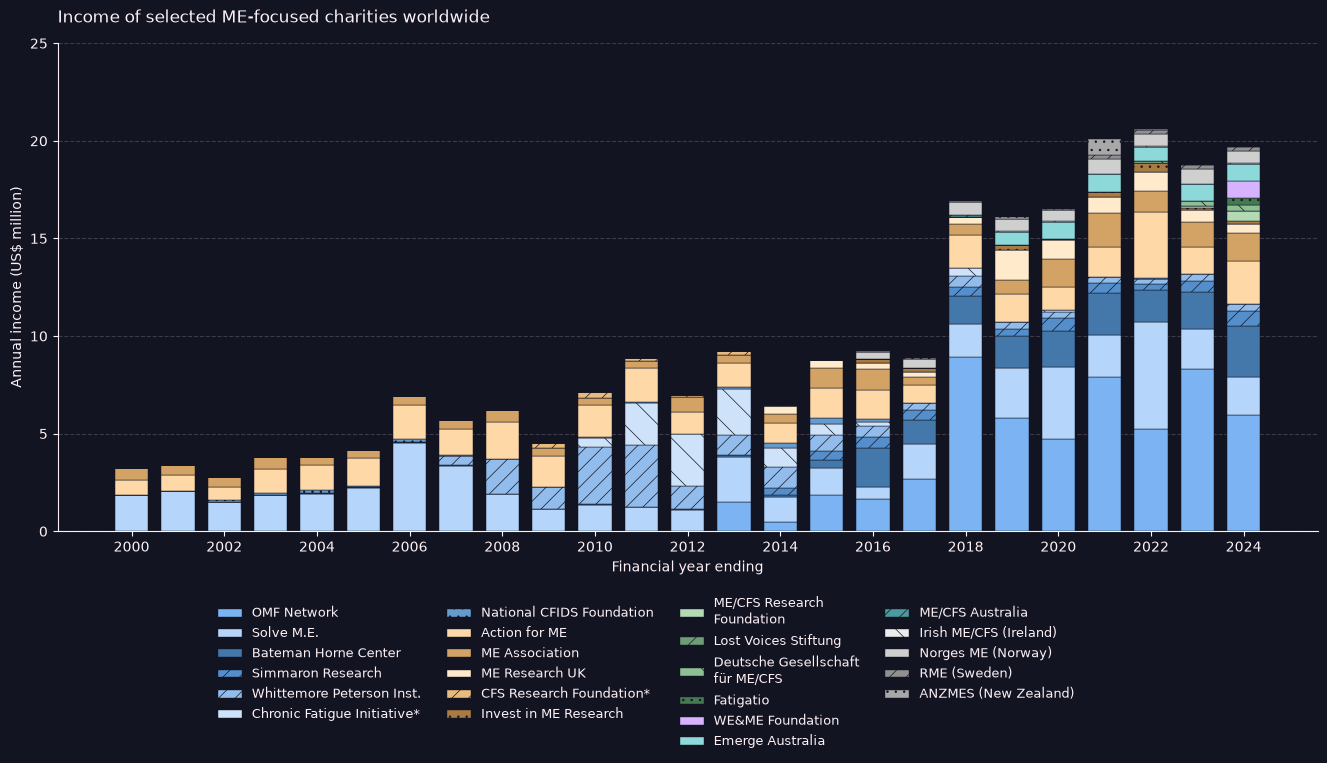

In [10]:
BG, FG = '#121421', '#FDF1F5'
plt.rcParams.update({'font.family':'DejaVu Sans', 'hatch.linewidth':.5})
fig, ax = plt.subplots(figsize=(14,8), facecolor=BG)
ax.set_facecolor(BG)
bottom = np.zeros(25)
for sid, label, colour, hatch in series:
    values = stacks[sid].fillna(0).to_numpy() / 1e6
    ax.bar(stacks.index, values, bottom=bottom, width=.72, color=colour, edgecolor=BG, linewidth=.35, hatch=hatch, label=label)
    bottom += values
ax.set_ylim(0,25)
ax.set_ylabel('Annual income (US$ million)', color=FG)
ax.set_xlabel('Financial year ending', color=FG)
ax.set_title('Income of selected ME-focused charities worldwide', color=FG, loc='left', pad=15)
ax.set_xticks(range(2000,2025,2))
ax.tick_params(colors=FG)
for side in ['top','right']: ax.spines[side].set_visible(False)
for side in ['bottom','left']: ax.spines[side].set_color(FG)
ax.set_axisbelow(True)
ax.grid(axis='y', linestyle='--', alpha=.18, color=FG)
handles = [Patch(facecolor=c, edgecolor=BG, hatch=h, label=n) for _,n,c,h in series]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=9, labelcolor=FG, frameon=False, bbox_to_anchor=(.5,.015))
fig.subplots_adjust(bottom=.3, left=.08, right=.98, top=.91)
fig.savefig(OUTPUT / 'charity-income-overview.png', dpi=180, facecolor=BG)
display(fig)
plt.close(fig)


## Interpretation and reuse

The figures support an overview of the charities represented, not an exact global growth rate or fully reconciled country totals. Earlier gaps include ME Research UK before 2014, CFS Research Foundation before 2009 and its closing transfer, Alison Hunter Memorial Foundation, parts of National CFIDS history, OFFER before 2004 and earlier national-association records. No gap is interpolated. A star identifies former standalone charities whose historical income remains included: Chronic Fatigue Initiative and CFS Research Foundation.

Country colours mean charity base, not where donations originate or research happens. Source accounts have different periods and accounting bases. Income and research expenditure are different measures.

CrunchME's original explanatory text, analysis and graphics are CC BY 4.0. Notebook code is MIT, with the licence at [CrunchME visual-notebooks](https://github.com/crunchme/visual-notebooks/blob/main/LICENSE-CODE). Source reports, regulator databases and ECB material retain their own rights. Public availability is not a blanket licence to republish those documents. This notebook includes selected financial facts, source links and original calculations only, without donor lists, signatures, source reports or private credentials. No charity, regulator or ECB endorsement is implied.

ECB rate information is available free from the linked ECB website. The conversion factors are CrunchME's derived period averages. ECB conditions require source credit, identification of modifications, and a free-source notice before payment and at access for paid distribution. This first website release does not enable paid Pro delivery pending that notice review.